In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
df = pd.read_csv("/content/hotel_bookings.csv")

In [ ]:
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [ ]:
df.shape

(119390, 32)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

- The dataset has 119,390 rows and 32 columns (about 29 MB in memory).
- Column types: 16 integer, 4 float, 12 object (text).
- The target is_canceled is an integer (0/1), so this is binary classification.

In [ ]:
df.describe()

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


- is_canceled has a mean of 0.370, so about 37% of bookings were canceled and 63% were not. The classes are moderately imbalanced.
- Initial target distribution: is_canceled has a mean of approximately 0.37, meaning about 37% of the original bookings were canceled and 63% were not.
- is_repeated_guest has a mean of 0.032, so only about 3% of guests are repeat guests.

**Skewed columns**
- `lead_time`: mean 104, median 69, max 737 → right-skewed
- `adr`: median 94.6, 75% = 126, max 5,400 → right-skewed with extreme outliers
- `days_in_waiting_list`: 75% = 0, max 391 → right-skewed


In [ ]:
print(df.isnull().sum())

hotel                                  0
is_canceled                            0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                               4
babies                                 0
meal                                   0
country                              488
market_segment                         0
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
agent                              16340
company         

- Children column is having 4 missing values
- country column is havig 488 missing values
- agent column is having 16340 missing values
- company column is having 112593 missig values

 **The agent and company columns are having more missing values**

In [ ]:
print(df.nunique())

hotel                                2
is_canceled                          2
lead_time                          479
arrival_date_year                    3
arrival_date_month                  12
arrival_date_week_number            53
arrival_date_day_of_month           31
stays_in_weekend_nights             17
stays_in_week_nights                35
adults                              14
children                             5
babies                               5
meal                                 5
country                            177
market_segment                       8
distribution_channel                 5
is_repeated_guest                    2
previous_cancellations              15
previous_bookings_not_canceled      73
reserved_room_type                  10
assigned_room_type                  12
booking_changes                     21
deposit_type                         3
agent                              333
company                            352
days_in_waiting_list     

In [ ]:
df.describe(include='object')

,hotel,arrival_date_month,meal,country,market_segment,distribution_channel,reserved_room_type,assigned_room_type,deposit_type,customer_type,reservation_status,reservation_status_date
count,119390,119390,119390,118902,119390,119390,119390,119390,119390,119390,119390,119390
unique,2,12,5,177,8,5,10,12,3,4,3,926
top,City Hotel,August,BB,PRT,Online TA,TA/TO,A,A,No Deposit,Transient,Check-Out,2015-10-21
freq,79330,13877,92310,48590,56477,97870,85994,74053,104641,89613,75166,1461


In [ ]:
df.duplicated().sum()

np.int64(31994)

No booking ID exists, so these rows can't be proven to be the same booking. They are removed to avoid duplicated information inflating the training data.

## **Step:2**

Handling Missing values

In [ ]:
df_clean = df.copy()

In [ ]:
df_clean.columns

Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'assigned_room_type', 'booking_changes', 'deposit_type', 'agent',
       'company', 'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date'],
      dtype='object')

In [ ]:
# Check and remove exact duplicate records

duplicate_count = df.duplicated().sum()

print("Duplicate rows:", duplicate_count)

df_clean = df.drop_duplicates().reset_index(drop=True)

print("Shape after removing duplicates:", df_clean.shape)

Duplicate rows: 31994
Shape after removing duplicates: (87396, 32)


In [ ]:
df_clean.drop(['reservation_status','reservation_status_date'],axis=1,inplace=True)

These features contains information that would not be available at the moment you make the prediction , so we droped those columns

In [ ]:
df_clean["has_company"] = df_clean["company"].notnull().astype(int)

Here the folat value is the ID of the company and if it has NaN it means no company is paying for that particular stay , so we are converting it into int value as 0 if no company is paying for stay and 1 if any company is paying for stay

In [ ]:
df_clean['has_agent'] = df_clean['agent'].notnull().astype(int)

Here the folat value is the ID of the agent and if it has NaN it means no agent is involed for that particular stay , so we are converting it into int value as 0 if an agent is not involved for stay and 1 if agent is involved for stay

In [ ]:
df_clean.drop(['company','agent'],axis=1,inplace=True)

In [ ]:
df_clean['children'].fillna(df_clean['children'].mode()[0],inplace=True)

/tmp/ipykernel_965/3231501490.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_clean['children'].fillna(df_clean['children'].mode()[0],inplace=True)


The column containing so many missing values so better to remove the column

In [ ]:
df_clean = df_clean.drop(columns=['country'])

In [ ]:
df_clean.isnull().sum()

,0
hotel,0
is_canceled,0
lead_time,0
arrival_date_year,0
arrival_date_month,0
arrival_date_week_number,0
arrival_date_day_of_month,0
stays_in_weekend_nights,0
stays_in_week_nights,0
adults,0


All the Null values are handled sucessfully

In [ ]:
for col in ["meal", "market_segment", "distribution_channel"]:
    print(df_clean[col].value_counts(), "\n")

meal
BB           67978
SC            9481
HB            9085
Undefined      492
FB             360
Name: count, dtype: int64 

market_segment
Online TA        51618
Offline TA/TO    13889
Direct           11804
Groups            4942
Corporate         4212
Complementary      702
Aviation           227
Undefined            2
Name: count, dtype: int64 

distribution_channel
TA/TO        69141
Direct       12988
Corporate     5081
GDS            181
Undefined        5
Name: count, dtype: int64 



**Data Types**

In [ ]:
df_clean.dtypes

,0
hotel,object
is_canceled,int64
lead_time,int64
arrival_date_year,int64
arrival_date_month,object
arrival_date_week_number,int64
arrival_date_day_of_month,int64
stays_in_weekend_nights,int64
stays_in_week_nights,int64
adults,int64


In [ ]:
df_clean['children'] = df_clean['children'].astype('int64')

In [ ]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 87396 entries, 0 to 87395
Data columns (total 29 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   hotel                           87396 non-null  object 
 1   is_canceled                     87396 non-null  int64  
 2   lead_time                       87396 non-null  int64  
 3   arrival_date_year               87396 non-null  int64  
 4   arrival_date_month              87396 non-null  object 
 5   arrival_date_week_number        87396 non-null  int64  
 6   arrival_date_day_of_month       87396 non-null  int64  
 7   stays_in_weekend_nights         87396 non-null  int64  
 8   stays_in_week_nights            87396 non-null  int64  
 9   adults                          87396 non-null  int64  
 10  children                        87396 non-null  int64  
 11  babies                          87396 non-null  int64  
 12  meal                            

**Handling Invalid rows**

In [ ]:
(df_clean["adr"] < 0).sum()


np.int64(1)

In [ ]:
# Filter out rows where adr is less than 0
df_clean = df_clean[df_clean["adr"] >= 0].reset_index(drop=True)

The pricing can't be negative.
Negative ADR is logically impossible because the average daily rate cannot be negative. Therefore, this record is treated as an invalid observation and removed.

In [ ]:
((df_clean["adults"] + df_clean["children"] + df_clean["babies"]) == 0).sum()


np.int64(166)

In [ ]:
((df_clean["stays_in_week_nights"] + df_clean["stays_in_weekend_nights"]) == 0).sum()

np.int64(651)

In [ ]:
zero_guests = (df_clean["adults"] + df_clean["children"] + df_clean["babies"]) == 0


In [ ]:
df_clean[zero_guests]["adr"].describe()

,adr
count,166.000000
mean,11.338373
std,32.845563
min,0.000000
25%,0.000000
50%,0.000000
75%,0.000000
max,200.000000


Dropping the 166 rows is well supported:

A booking with no guests isn't a real booking.
Most have no price either, so they behave like placeholders.
166 rows is about 0.2% of the data, so you lose almost nothing.

In [ ]:
zero_nights = (df_clean["stays_in_week_nights"] + df_clean["stays_in_weekend_nights"]) == 0


In [ ]:
df_clean[zero_nights]["adr"].describe()

,adr
count,651.0
mean,0.0
std,0.0
min,0.0
25%,0.0
50%,0.0
75%,0.0
max,0.0


Records with negative ADR, zero guests, or zero total nights were treated as invalid based on the logical meaning of the booking variables. Negative ADR is impossible, a booking with zero guests is not meaningful for this analysis, and a booking with zero total nights does not represent an actual overnight stay.

In [ ]:
invalid = (df_clean["adr"] < 0) | zero_guests | zero_nights

In [ ]:
invalid.sum()

np.int64(757)

In [ ]:
df_clean = df_clean[~invalid].reset_index(drop=True)
df_clean.shape

(86638, 29)

In [ ]:
print(df_clean.shape)
print((df_clean["adr"] < 0).sum())
print(((df_clean["adults"] + df_clean["children"] + df_clean["babies"]) == 0).sum())
print(((df_clean["stays_in_week_nights"] + df_clean["stays_in_weekend_nights"]) == 0).sum())
df_clean["is_canceled"].value_counts(normalize=True)

(86638, 29)
0
0
0


,proportion
is_canceled,
0,0.723147
1,0.276853


In [ ]:
df_clean.columns

Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'market_segment', 'distribution_channel', 'is_repeated_guest',
       'previous_cancellations', 'previous_bookings_not_canceled',
       'reserved_room_type', 'assigned_room_type', 'booking_changes',
       'deposit_type', 'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'has_company', 'has_agent'],
      dtype='object')

Column names were inspected and found to be consistent, unique, and free from leading/trailing spaces. Therefore, no renaming was required.

**Final target distribution**

In [ ]:
# Target Variable Distribution

print(df_clean["is_canceled"].value_counts())

print("\nPercentage Distribution:")
print(df_clean["is_canceled"].value_counts(normalize=True) * 100)

is_canceled
0    62652
1    23986
Name: count, dtype: int64

Percentage Distribution:
is_canceled
0    72.314689
1    27.685311
Name: proportion, dtype: float64


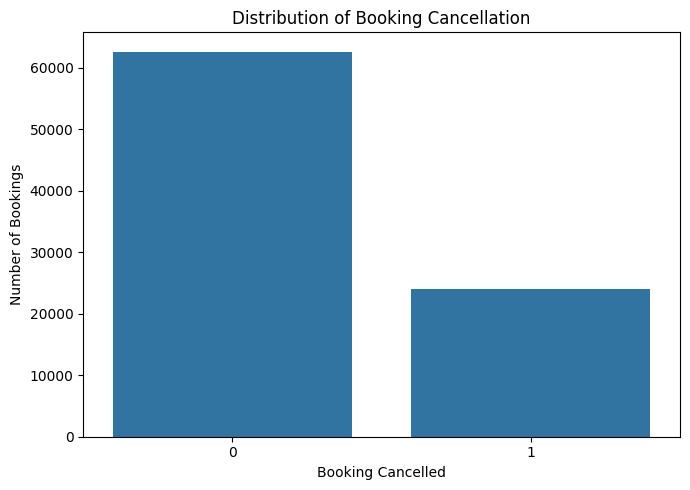

In [ ]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df_clean,
    x="is_canceled"
)

plt.title("Distribution of Booking Cancellation")
plt.xlabel("Booking Cancelled")
plt.ylabel("Number of Bookings")

plt.tight_layout()
plt.show()

The cleaned dataset contains both canceled and non-canceled bookings, with non-canceled bookings forming the majority. The target variable is moderately imbalanced, so accuracy alone should not be relied upon during model evaluation. Precision, recall, F1-score and the confusion matrix should also be considered.

## **EDA**

**Univariate Analysis**

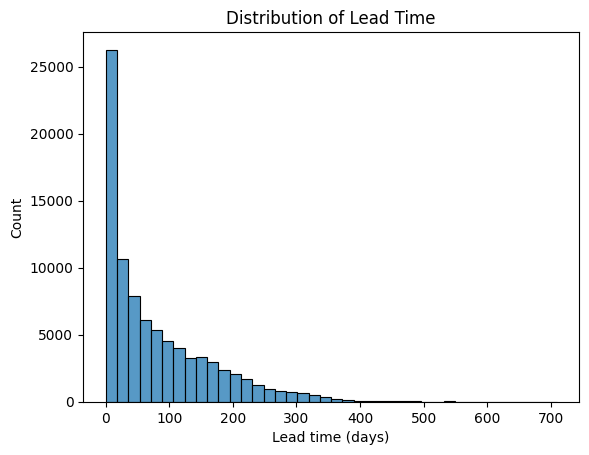

Skewness: 1.4230959574459816


In [ ]:
sns.histplot(df_clean["lead_time"], bins=40)
plt.title("Distribution of Lead Time")
plt.xlabel("Lead time (days)")
plt.show()

print("Skewness:", df_clean["lead_time"].skew())

- Only less number of people are booked in advance for 300+ days ahead
- Most of the bookings are happening very close to the  staying days (25000+ bookings)
- The graph is showing that is was right skewed

In [ ]:
print(df_clean['lead_time'].mean())
print(df_clean['lead_time'].median())
print((df_clean['lead_time']<= 30).mean() * 100)
print((df_clean['lead_time']>= 300).mean() * 100)

80.29176573789792
50.0
39.34647614210854
2.666266534315197


- Shape: lead time is right-skewed (skewness 1.43). The median is 50 days and the mean is 80 days.
- Short lead times: About 30% of bookings are made within a month of arrival.
- Long tail: only about 2% of bookings are made more than 300 days ahead.
- Why it matters: The mean (80) is higher than the median (50) because a small number of very large lead times pulls the mean up . This matters because Models that are sensitive to scale and distribution, like Logistic Regression and SVM from Sprint 2, can be thrown off by a long tail . In Step 5, I will check the extreme values with boxplot and IQR method,then decide whether to cap them or apply any transform technique .

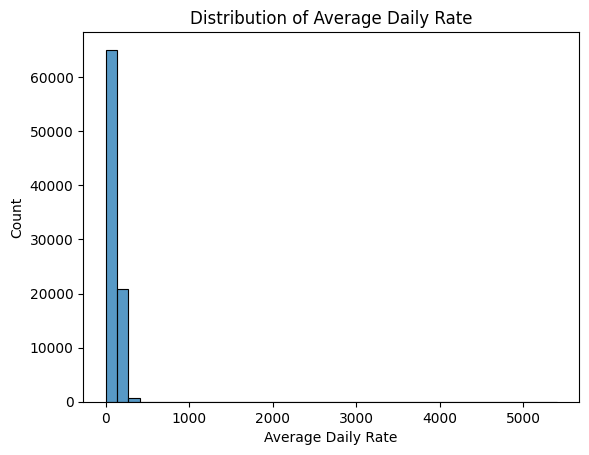

Skewness: 11.429627672121374


In [ ]:
sns.histplot(df_clean['adr'],bins = 40)
plt.title('Distribution of Average Daily Rate')
plt.xlabel('Average Daily Rate')
plt.show()
print('Skewness:',df_clean['adr'].skew())

In [ ]:
print(df_clean['adr'].describe())
print((df_clean['adr'] == 0).sum())
print((df_clean['adr'] > 2000).sum())
print((df_clean['adr']).nlargest(5))

count    86638.000000
mean       107.245945
std         54.365064
min          0.000000
25%         72.900000
50%         99.000000
75%        134.437500
max       5400.000000
Name: adr, dtype: float64
1052
1
38346    5400.0
79995     510.0
11571     508.0
73801     451.5
9902      450.0
Name: adr, dtype: float64


- Shape: skewness = right skewd(Skewness: 11.445863443195817); the median is 99 and the mean is 107;Mean is slightly above the median.
-  Typical range: the middle 50% of bookings fall between 72.9 to 134.57 per night.
- Unusual values: the maximum is 5400, which is far above 75th percentile(134.57) of bookings; 1052 rows have adr = 0.
- Only 1 booking has adr above 2,000 (5,400), far above the next highest value of 510 .
- The value 5,400 is an extreme isolated observation compared with the rest of the ADR distribution. It will be investigated during the outlier-treatment stage before deciding whether to remove, cap, or transform it.

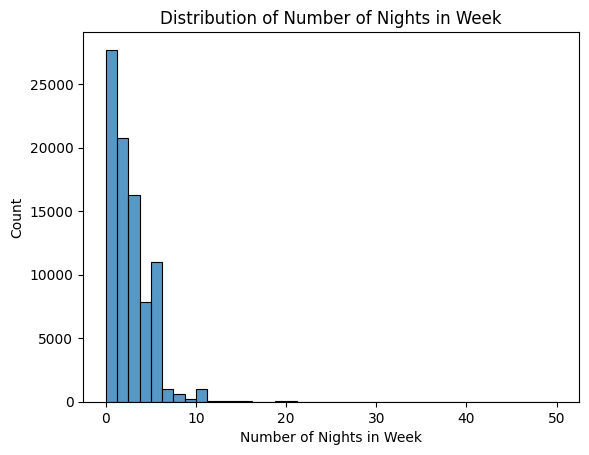

Skewness: 2.5991370999267343


In [ ]:
sns.histplot(df_clean['stays_in_week_nights'],bins=40)
plt.title('Distribution of Number of Nights in Week')
plt.xlabel('Number of Nights in Week')
plt.show()
print('Skewness:',df_clean['stays_in_week_nights'].skew())

In [ ]:
print(df_clean["stays_in_week_nights"].describe())
print((df_clean["stays_in_week_nights"] == 0).mean() * 100)
print((df_clean["stays_in_week_nights"] > 10).sum())

count    86638.000000
mean         2.641785
std          2.035172
min          0.000000
25%          1.000000
50%          2.000000
75%          4.000000
max         50.000000
Name: stays_in_week_nights, dtype: float64
6.372492439807013
332


In [ ]:
col = df_clean["stays_in_week_nights"]
print((col > 8.5).sum())     # IQR upper fence: 4 + 1.5 * (4 - 1) = 8.5
print((col > 14).sum())
print((col > 30).sum())

1514
191
7


- Shape: the distribution is right-skewed (skewness 2.59). Most stays are short: the median is 2.0 nights and the mean is 2.64 nights.
- Typical range: the middle 50% of bookings include 1.0 to 4.0 weeknights (the 25% and 75% values).
- Unusual values: a few bookings have very long stays, with a maximum of 50 weeknights, far above the 75th percentile of 4.0. About 6.36% of rows have 0 weeknights, which is valid because these guests stay only on weekend nights (rows with zero nights in total were already removed).
- Why it matters and what I'll do: a handful of very long stays stretch the right tail and will pull up the mean. In Step 5, I will check the extreme values with a boxplot and the IQR rule (upper fence 8.5 nights). 7 rows exceed 30 nights.

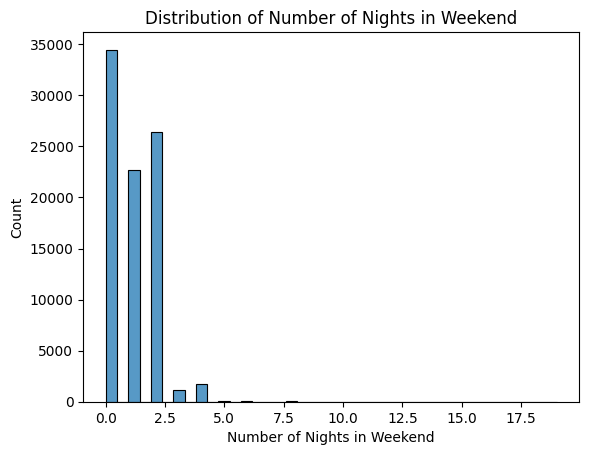

Skewness: 1.3353174412813782


In [ ]:
sns.histplot(df_clean['stays_in_weekend_nights'],bins=40)
plt.title('Distribution of Number of Nights in Weekend')
plt.xlabel('Number of Nights in Weekend')
plt.show()
print('Skewness:',df_clean['stays_in_weekend_nights'].skew())

In [ ]:
col = df_clean["stays_in_weekend_nights"]
print(col.describe())
print((col == 0).mean() * 100)
print((col > 4).sum())

count    86638.000000
mean         1.011427
std          1.027495
min          0.000000
25%          0.000000
50%          1.000000
75%          2.000000
max         19.000000
Name: stays_in_weekend_nights, dtype: float64
39.78277430226921
281


In [ ]:
col = df_clean["stays_in_weekend_nights"]
print((col > 5).sum())
print((col > 5).mean() * 100)
print(df_clean[col > 5][["stays_in_week_nights", "adr", "is_canceled"]].describe())

213
0.24585055056672592
       stays_in_week_nights         adr  is_canceled
count            213.000000  213.000000   213.000000
mean              18.262911   73.470516     0.521127
std                5.386600   37.821177     0.500730
min               10.000000    0.000000     0.000000
25%               15.000000   49.950000     0.000000
50%               18.000000   68.340000     1.000000
75%               20.000000   91.090000     1.000000
max               50.000000  231.810000     1.000000


- Shape: the distribution is right-skewed (skewness 1.33), which is noticeably lower than the weeknights column (2.59). The median is 1.0 nights and the mean is 1.01 nights.
- Typical range: the middle 50% of bookings include 0.0 to 1.0 weekend nights. From the plot, nearly all bookings fall between 0 and 4 weekend nights.
- Unusual values: the longest stays reach a maximum of 19 weekend nights, far above the 75th percentile of 2.0. About 39.77% of rows have 0 weekend nights (stays that cover only weekdays), and 278 rows exceed 4.
- Why it matters and what I'll do: the tail is much thinner and shorter than for weeknights, so it is less of an outlier problem. In Step 5, I will check it with a boxplot and the IQR rule (upper fence 5.0) , and compare it with stays_in_week_nights before deciding to cap or keep the extreme values, because only 211 rows (about 0.24%) exceed 5 weekend nights, and these also have long weeknight stays, so they look like genuine long stays and not errors.
- The extreme values may represent genuine long stays. They will be investigated using boxplots and the IQR method during the outlier-treatment stage before deciding whether to keep, cap, or transform them.

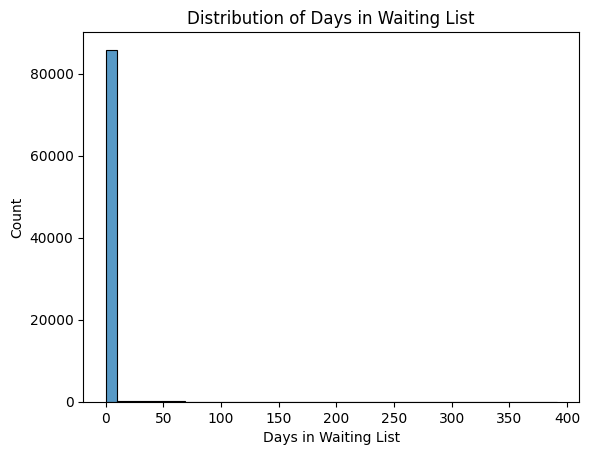

Skewness: 19.42207354760872


In [ ]:
sns.histplot(df_clean['days_in_waiting_list'],bins = 40)
plt.title('Distribution of Days in Waiting List')
plt.xlabel('Days in Waiting List')
plt.show()
print('Skewness:',df_clean['days_in_waiting_list'].skew())

In [ ]:
col = df_clean["days_in_waiting_list"]
print(col.describe())
print((col == 0).mean() * 100)
print((col > 0).sum())
print((col > 0).mean() * 100)
print(col[col > 0].describe()  )   # summary of the bookings that did wait

count    86638.000000
mean         0.750260
std         10.029481
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max        391.000000
Name: days_in_waiting_list, dtype: float64
99.01428934185923
854
0.9857106581407697
count    854.000000
mean      76.113583
std       66.886599
min        1.000000
25%       33.000000
50%       59.000000
75%       99.000000
max      391.000000
Name: days_in_waiting_list, dtype: float64


- Shape: the distribution is extremely right-skewed (skewness 19.75), far higher than any other column so far. The median and the 75th percentile are both 0.0, so the plot is almost a single bar.
- Typical range: about 99.02% of bookings have exactly 0 days on the waiting list, so a typical booking never waited at all.
- Unusual values: only 841 rows (about 0.97%) have any waiting time, and the longest wait is 391 days. The mean (0.73) is far above the median (0.0), pulled up entirely by this small group.


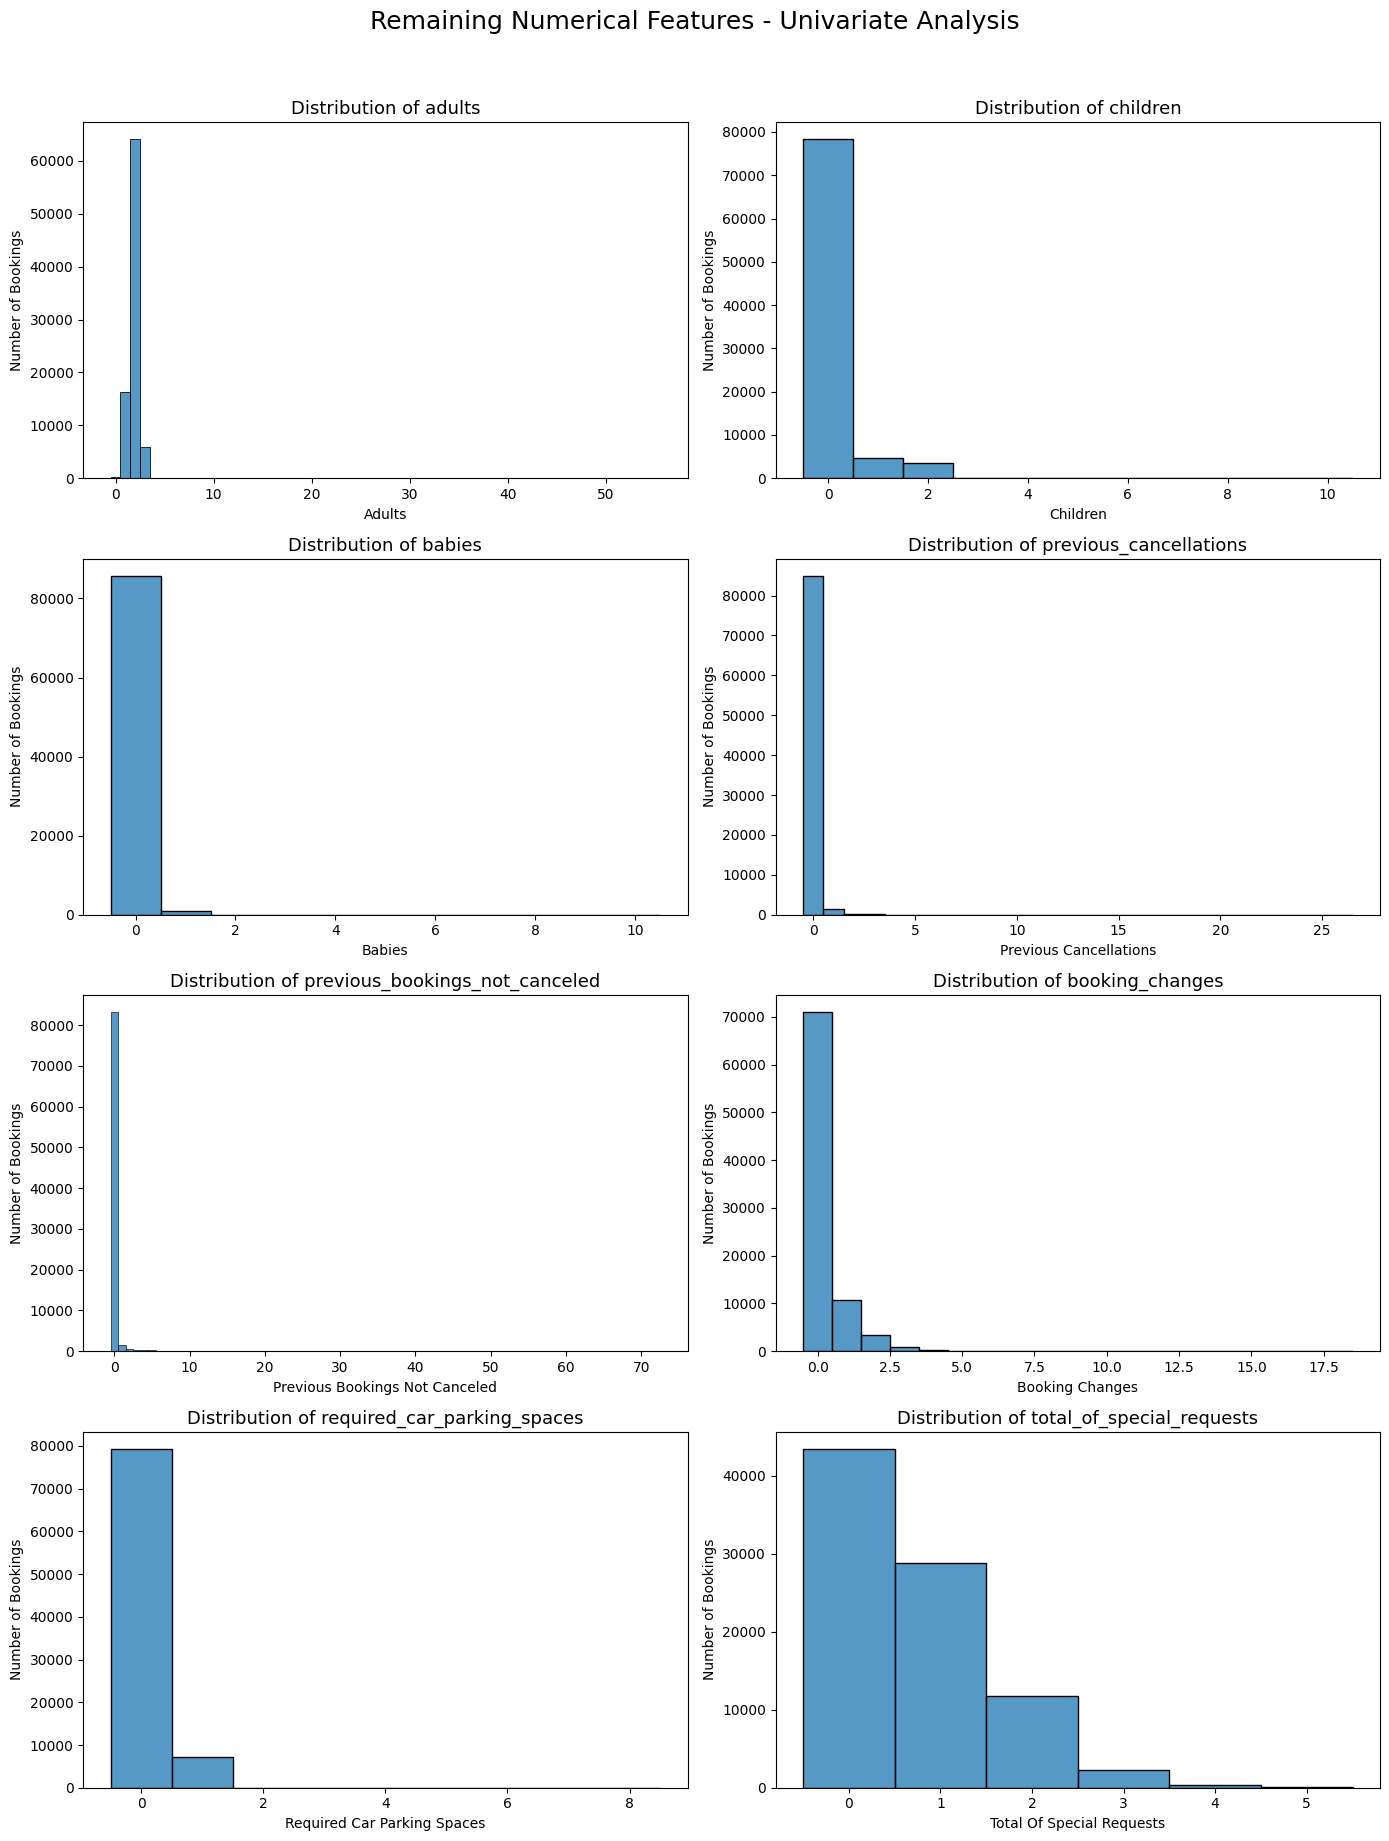

In [ ]:
# Remaining Numerical Features - Univariate Analysis

remaining_numeric_cols = [
    "adults",
    "children",
    "babies",
    "previous_cancellations",
    "previous_bookings_not_canceled",
    "booking_changes",
    "required_car_parking_spaces",
    "total_of_special_requests"
]

fig, axes = plt.subplots(4, 2, figsize=(14, 18))

for ax, col in zip(axes.flatten(), remaining_numeric_cols):

    sns.histplot(
        data=df_clean,
        x=col,
        discrete=True,
        ax=ax
    )

    ax.set_title(f"Distribution of {col}", fontsize=13)
    ax.set_xlabel(col.replace("_", " ").title())
    ax.set_ylabel("Number of Bookings")

plt.suptitle(
    "Remaining Numerical Features - Univariate Analysis",
    fontsize=18,
    y=1.02
)

plt.tight_layout()
plt.show()

In [ ]:
summary = pd.DataFrame({
    "Mean": df_clean[remaining_numeric_cols].mean(),
    "Median": df_clean[remaining_numeric_cols].median(),
    "Min": df_clean[remaining_numeric_cols].min(),
    "Max": df_clean[remaining_numeric_cols].max(),
    "Skewness": df_clean[remaining_numeric_cols].skew()
})

summary

,Mean,Median,Min,Max,Skewness
adults,1.880503,2.0,0,55,20.479083
children,0.139304,0.0,0,10,3.453979
babies,0.010861,0.0,0,10,21.158048
previous_cancellations,0.030564,0.0,0,26,34.229414
previous_bookings_not_canceled,0.184388,0.0,0,72,20.435155
booking_changes,0.268150,0.0,0,18,5.078973
required_car_parking_spaces,0.084697,0.0,0,8,3.479767
total_of_special_requests,0.700189,0.0,0,5,1.081052


Most of the remaining numerical features are heavily concentrated at zero or low values. children, babies, previous_cancellations, previous_bookings_not_canceled, and required_car_parking_spaces have median values of zero, indicating that these events are uncommon for most bookings. adults has a median of 2, showing that bookings typically involve two adults. booking_changes is also mostly zero, indicating that most reservations are not modified after booking. total_of_special_requests has a relatively broader distribution, although most bookings still contain few or no special requests. Several variables exhibit strong right-skewness because a small number of bookings have unusually high values. These extreme observations will be investigated during the outlier-treatment stage rather than removed at this stage.

**Categorical columns univariate analysis**

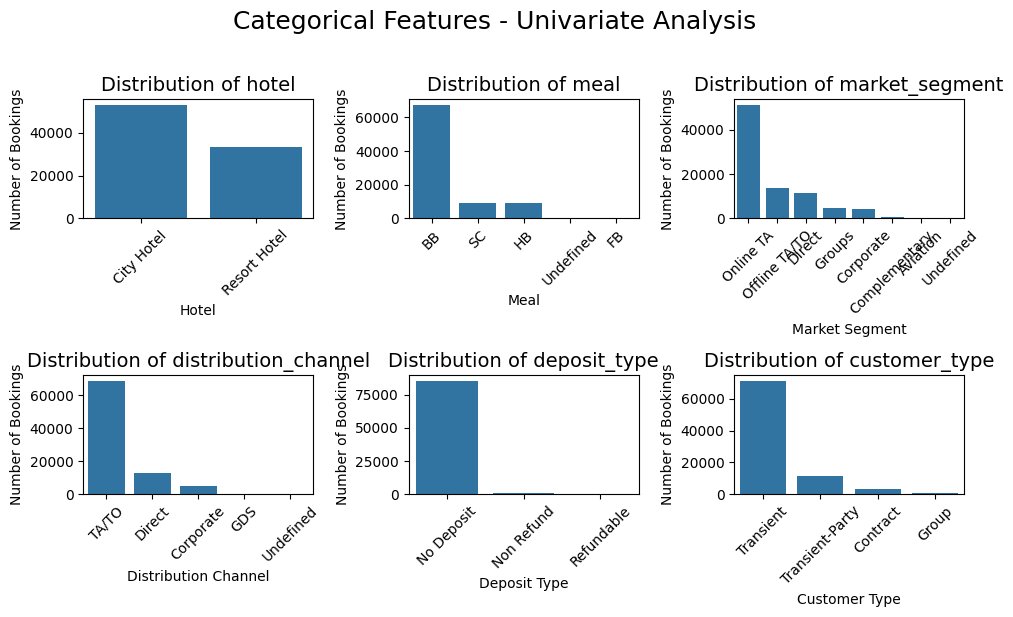

In [ ]:
# Main Categorical Univariate Analysis

categorical_cols = [
    "hotel",
    "meal",
    "market_segment",
    "distribution_channel",
    "deposit_type",
    "customer_type"
]

fig, axes = plt.subplots(2,3, figsize=(10,6))

for ax, col in zip(axes.flatten(), categorical_cols):

    order = df_clean[col].value_counts().index

    sns.countplot(
        data=df_clean,
        x=col,
        order=order,
        ax=ax
    )

    ax.set_title(f"Distribution of {col}", fontsize=14)
    ax.set_xlabel(col.replace("_", " ").title())
    ax.set_ylabel("Number of Bookings")

    # Rotate labels for readability
    ax.tick_params(axis="x", rotation=45)

plt.suptitle(
    "Categorical Features - Univariate Analysis",
    fontsize=18,
    y=1.02
)

plt.tight_layout()
plt.show()

### Insights: Categorical Features – Univariate Analysis

1. **Hotel Type:** City Hotels receive more bookings than Resort Hotels, indicating a higher representation of City Hotels in the dataset.

2. **Meal:** BB (Bed & Breakfast) is the most preferred meal plan, accounting for the majority of bookings. SC (Self Catering) and HB (Half Board) have considerably fewer bookings, while FB (Full Board) and Undefined are rarely selected.

3. **Market Segment:** Online Travel Agents (Online TA) contribute the highest number of bookings, followed by Offline TA/TO and Direct bookings. This indicates that travel agencies, particularly online platforms, are major booking sources.

4. **Distribution Channel:** TA/TO (Travel Agents/Tour Operators) is the dominant distribution channel, followed by Direct and Corporate bookings. GDS contributes very few bookings, indicating a strong reliance on travel intermediaries.

5. **Deposit Type:** The vast majority of bookings fall under the No Deposit category. Non Refund and Refundable bookings are extremely rare, showing a highly imbalanced distribution.

6. **Customer Type:** Transient customers account for the majority of bookings, followed by Transient-Party customers. Contract and Group bookings represent only a small proportion of the dataset.

**Overall Insight:** Hotel bookings are concentrated in a few dominant categories, particularly City Hotels, BB meal plans, Online Travel Agents, No Deposit reservations and Transient customers. Several categorical features have highly imbalanced distributions, which should be considered during feature encoding and model development.

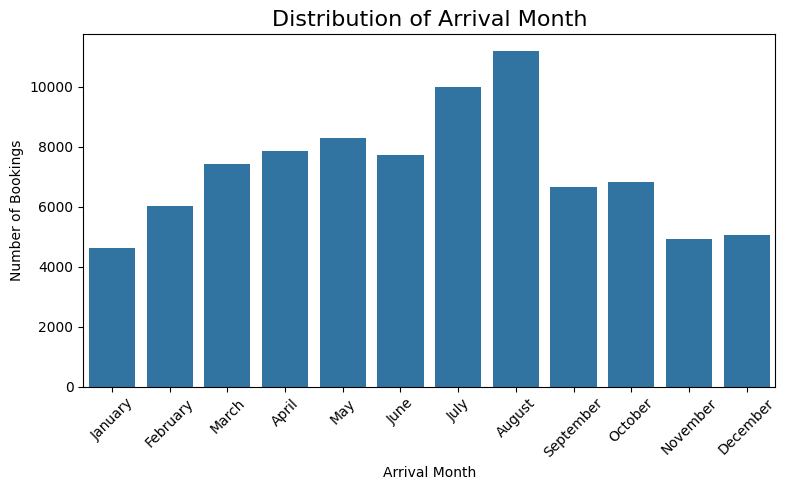

In [ ]:
# Month order
month_order = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

plt.figure(figsize=(8,5))

sns.countplot(
    data=df_clean,
    x="arrival_date_month",
    order=month_order
)

plt.title("Distribution of Arrival Month", fontsize=16)
plt.xlabel("Arrival Month")
plt.ylabel("Number of Bookings")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Hotel bookings show clear seasonal variation. August has the highest number of bookings, followed by July, while January has the lowest. Booking volume generally increases toward the middle of the year, peaks during July–August, and declines afterward. This suggests that hotel demand varies considerably across arrival months.

Portugal is the dominant source of bookings among the top 10 countries, followed by the United Kingdom, France, Spain, and Germany. The remaining countries contribute considerably fewer bookings. Overall, the distribution is highly concentrated and is primarily dominated by European countries.

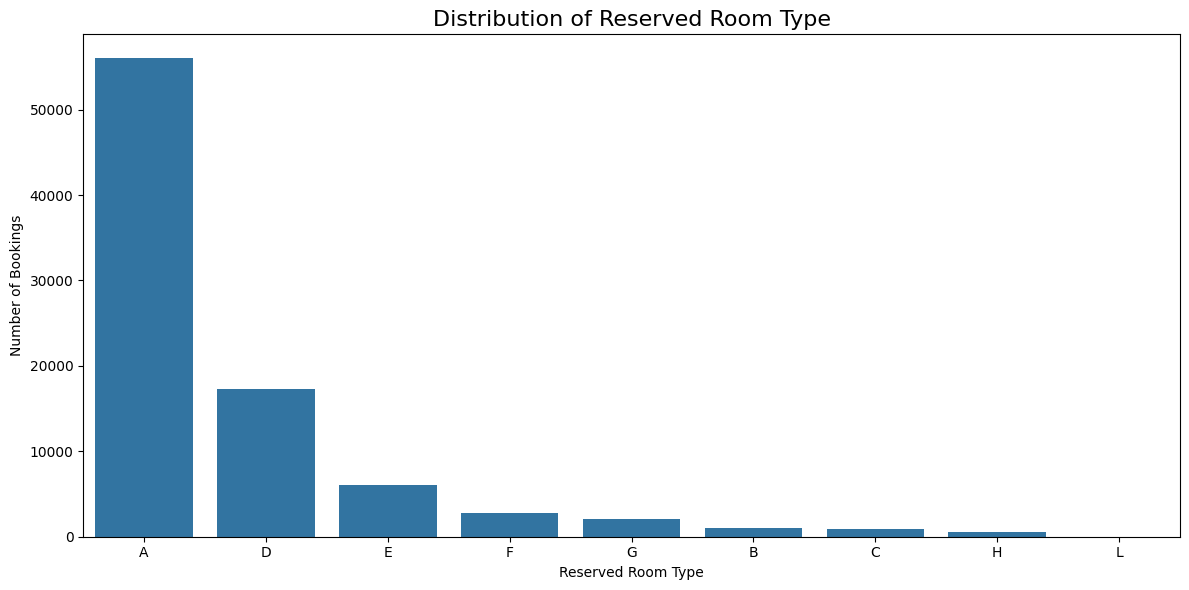

In [ ]:
# Distribution of Reserved Room Type

room_counts = df_clean["reserved_room_type"].value_counts()

plt.figure(figsize=(12, 6))

sns.barplot(
    x=room_counts.index,
    y=room_counts.values
)

plt.title("Distribution of Reserved Room Type", fontsize=16)
plt.xlabel("Reserved Room Type")
plt.ylabel("Number of Bookings")

plt.tight_layout()
plt.show()

Room Type A is overwhelmingly the most frequently reserved room type, followed by Room Type D. The remaining room types account for substantially fewer bookings, with Room Type L being the least common. Overall, the distribution is highly imbalanced and strongly concentrated toward Room Type A.

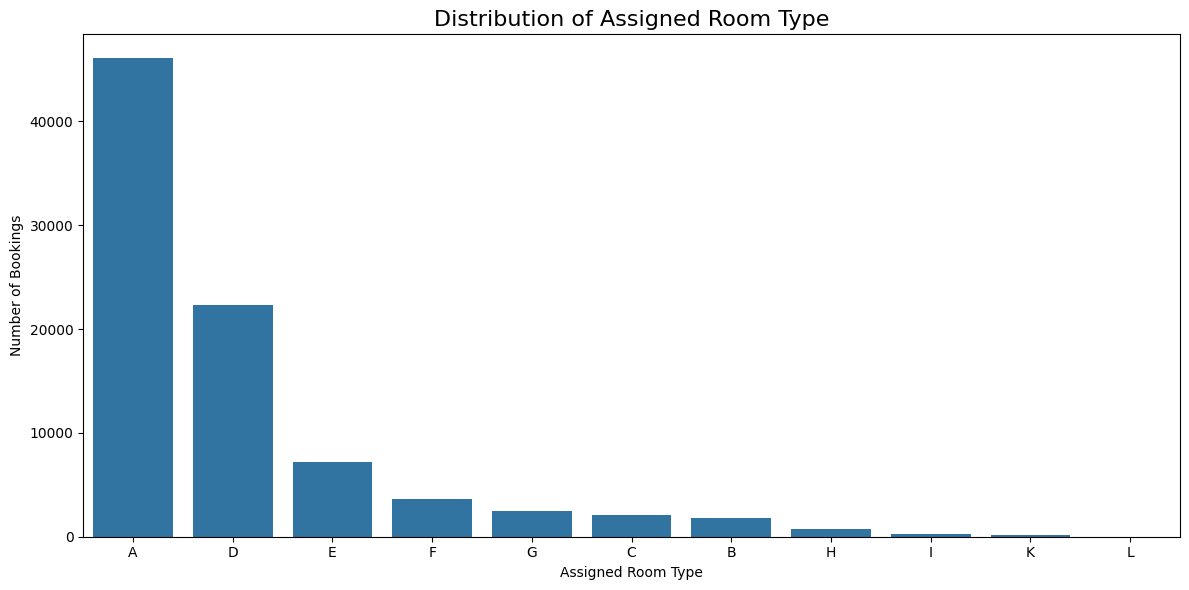

In [ ]:
# Distribution of Assigned Room Type

room_counts = df_clean["assigned_room_type"].value_counts()

plt.figure(figsize=(12, 6))

sns.barplot(
    x=room_counts.index,
    y=room_counts.values
)

plt.title("Distribution of Assigned Room Type", fontsize=16)
plt.xlabel("Assigned Room Type")
plt.ylabel("Number of Bookings")

plt.tight_layout()
plt.show()

Room Type A is the most frequently assigned room type, followed by Room Type D. The remaining room types account for substantially fewer bookings, with H, I, K, and L being rarely assigned. Overall, the assigned room type distribution is highly imbalanced and concentrated mainly in Types A and D.

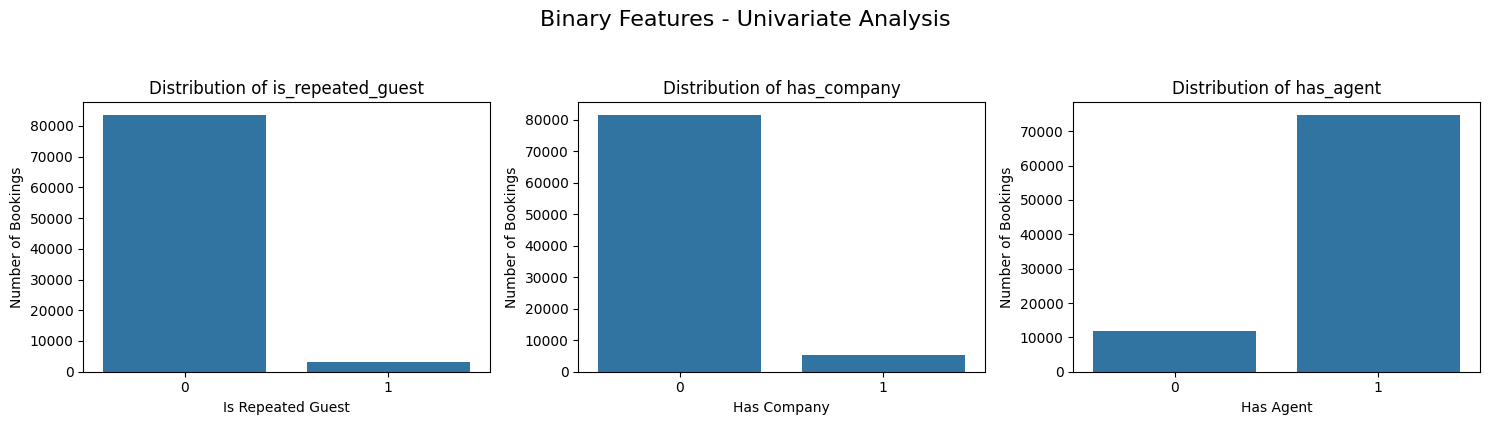

In [ ]:
binary_cols = [
    "is_repeated_guest",
    "has_company",
    "has_agent"
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, binary_cols):

    sns.countplot(
        data=df_clean,
        x=col,
        ax=ax
    )

    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col.replace("_", " ").title())
    ax.set_ylabel("Number of Bookings")

plt.suptitle(
    "Binary Features - Univariate Analysis",
    fontsize=16,
    y=1.05
)

plt.tight_layout()
plt.show()

- is_repeated_guest: The majority of bookings are from non-repeated guests (0), while only a small proportion are from repeated guests (1). This indicates that repeat guests represent a relatively small segment of the bookings.
- has_company: Most bookings do not have a company ID recorded (0), while a much smaller number have a company ID recorded (1). This indicates that company-associated bookings form a relatively small proportion of the dataset.
- has_agent: The majority of bookings have an agent ID recorded (1), while a smaller proportion do not (0). This indicates that travel-agent involvement is common in the bookings.
- Overall Insight: The three binary features show noticeably different distributions. Repeat guests and company-associated bookings represent relatively small proportions of the dataset, whereas agent-associated bookings represent the majority.

**Bi-variate Analysis**

In [ ]:
hotel_cancel_rate = (
    df_clean.groupby("hotel")["is_canceled"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

hotel_cancel_rate

,is_canceled
hotel,
City Hotel,30.205682
Resort Hotel,23.705909


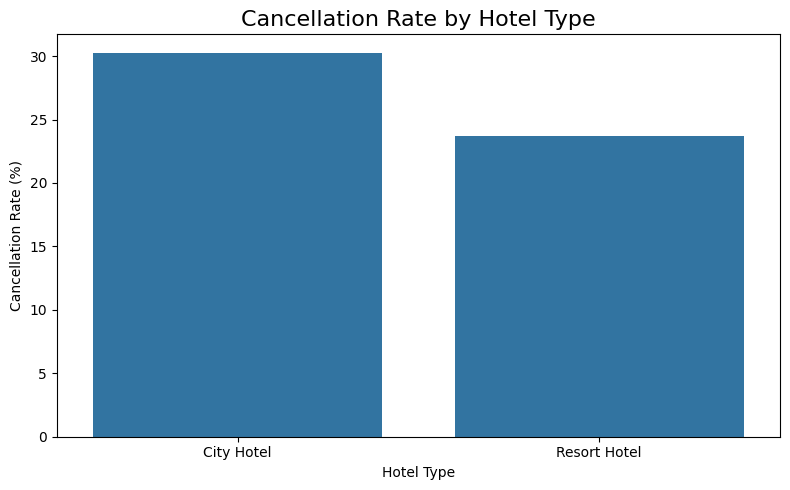

In [ ]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=hotel_cancel_rate.index,
    y=hotel_cancel_rate.values
)

plt.title("Cancellation Rate by Hotel Type", fontsize=16)
plt.xlabel("Hotel Type")
plt.ylabel("Cancellation Rate (%)")

plt.tight_layout()
plt.show()

City Hotels have a higher cancellation rate (30.20%) compared with Resort Hotels (23.71%). This indicates that hotel type is associated with differences in booking cancellation behavior, with City Hotels experiencing approximately 6.49 percentage points higher cancellation rate.


In [ ]:
hotel_summary = df_clean.groupby("hotel").agg(
    total_bookings=("is_canceled", "count"),
    cancellations=("is_canceled", "sum"),
    cancellation_rate=("is_canceled", "mean")
)

hotel_summary["cancellation_rate"] *= 100

hotel_summary

,total_bookings,cancellations,cancellation_rate
hotel,,,
City Hotel,53043,16022,30.205682
Resort Hotel,33595,7964,23.705909


In [ ]:
meal_cancel_rate = (
    df_clean.groupby("meal")["is_canceled"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

meal_cancel_rate

,is_canceled
meal,
SC,35.662315
FB,27.576602
HB,27.120709
BB,26.733217
Undefined,16.907216


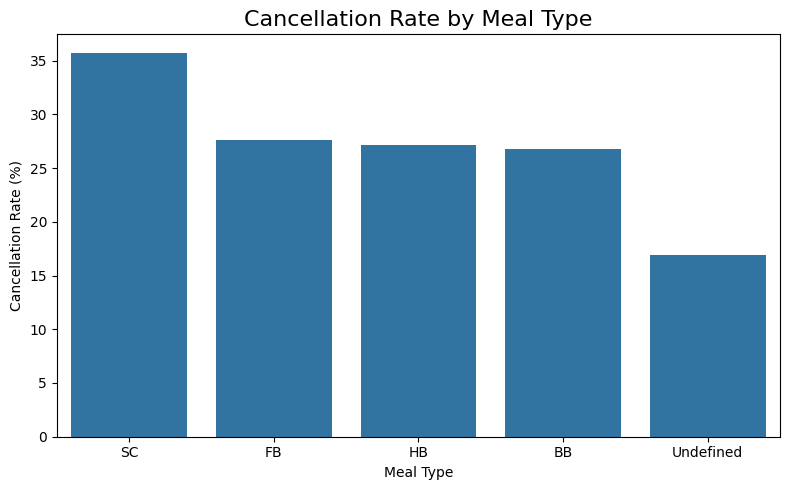

In [ ]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=meal_cancel_rate.index,
    y=meal_cancel_rate.values
)

plt.title("Cancellation Rate by Meal Type", fontsize=16)
plt.xlabel("Meal Type")
plt.ylabel("Cancellation Rate (%)")
plt.tight_layout()
plt.show()

The SC (Self Catering) meal type has the highest cancellation rate at 35.66%, followed by FB (Full Board) at 27.58%, HB (Half Board) at 27.12%, and BB (Bed & Breakfast) at 26.73%. The Undefined meal category has the lowest cancellation rate at 16.91%. Overall, cancellation rates vary across meal types, with SC bookings showing a noticeably higher cancellation rate than the other defined meal categories.

In [ ]:
meal_summary = df_clean.groupby("meal").agg(
    total_bookings=("is_canceled", "count"),
    cancellations=("is_canceled", "sum"),
    cancellation_rate=("is_canceled", "mean")
)

meal_summary["cancellation_rate"] *= 100

meal_summary

,total_bookings,cancellations,cancellation_rate
meal,,,
BB,67418,18023,26.733217
FB,359,99,27.576602
HB,9030,2449,27.120709
SC,9346,3333,35.662315
Undefined,485,82,16.907216


In [ ]:
market_cancel_rate = (
    df_clean.groupby("market_segment")["is_canceled"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

market_cancel_rate

,is_canceled
market_segment,
Undefined,100.000000
Online TA,35.546456
Groups,27.213249
Aviation,19.819820
Offline TA/TO,14.953815
Direct,14.872983
Corporate,12.202166
Complementary,12.170088


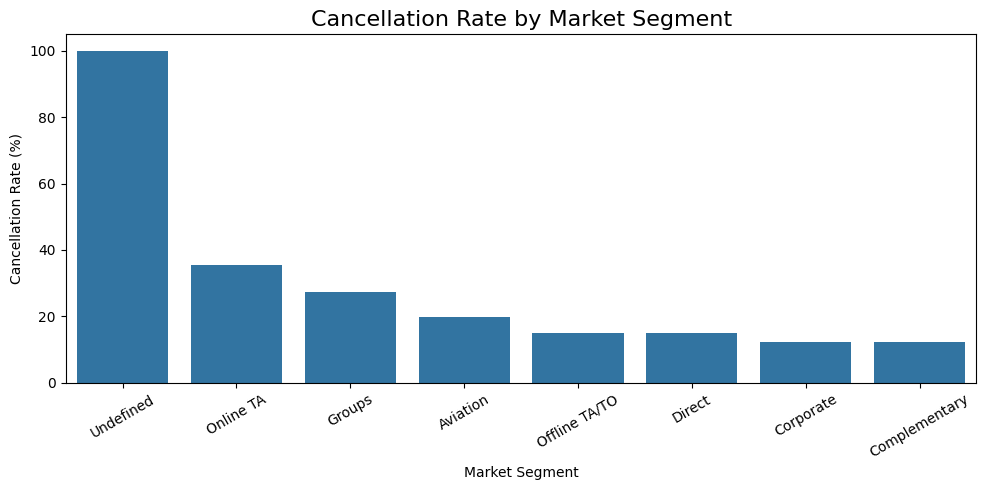

In [ ]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=market_cancel_rate.index,
    y=market_cancel_rate.values
)

plt.title("Cancellation Rate by Market Segment", fontsize=16)
plt.xlabel("Market Segment")
plt.ylabel("Cancellation Rate (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

The Online TA (Travel Agents) segment has the highest cancellation rate at 35.55%, followed by Groups at 27.21% and Aviation at 19.82%. Offline TA/TO and Direct bookings have similar cancellation rates of around 15%, while Corporate (12.20%) and Complementary (12.17%) have the lowest cancellation rates. Overall, cancellation behavior varies considerably across market segments, with Online TA bookings showing the highest cancellation rate.

In [ ]:
market_summary = df_clean.groupby("market_segment").agg(
    total_bookings=("is_canceled", "count"),
    cancellations=("is_canceled", "sum"),
    cancellation_rate=("is_canceled", "mean")
)

market_summary["cancellation_rate"] *= 100

market_summary.sort_values(
    "cancellation_rate",
    ascending=False
)

,total_bookings,cancellations,cancellation_rate
market_segment,,,
Undefined,2,2,100.000000
Online TA,51285,18230,35.546456
Groups,4891,1331,27.213249
Aviation,222,44,19.819820
Offline TA/TO,13749,2056,14.953815
Direct,11652,1733,14.872983
Corporate,4155,507,12.202166
Complementary,682,83,12.170088


In [ ]:
channel_cancel_rate = (
    df_clean.groupby("distribution_channel")["is_canceled"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

channel_cancel_rate

,is_canceled
distribution_channel,
Undefined,80.000000
TA/TO,31.153224
GDS,20.224719
Direct,14.980864
Corporate,12.817437


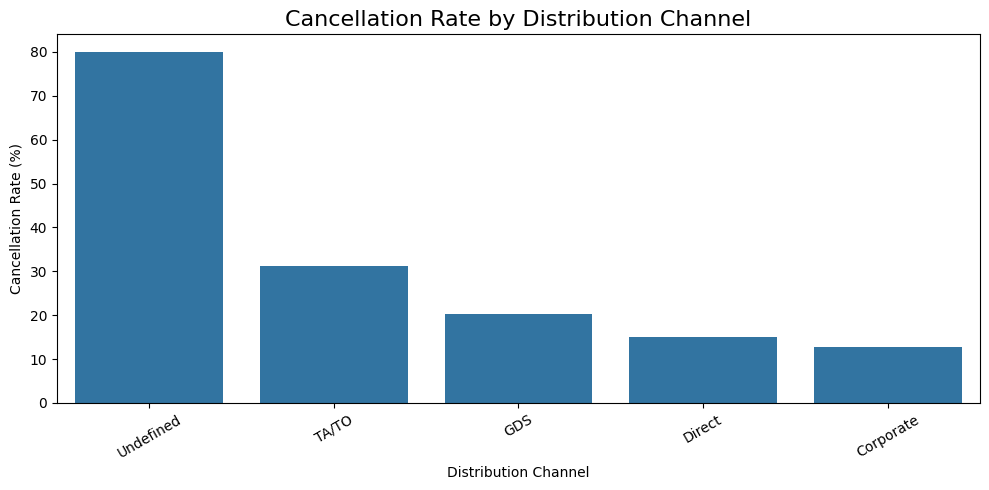

In [ ]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=channel_cancel_rate.index,
    y=channel_cancel_rate.values
)

plt.title("Cancellation Rate by Distribution Channel", fontsize=16)
plt.xlabel("Distribution Channel")
plt.ylabel("Cancellation Rate (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

The TA/TO (Travel Agents/Tour Operators) distribution channel has the highest cancellation rate at 31.15%, followed by GDS at 20.22%. Direct bookings have a cancellation rate of 14.98%, while Corporate bookings have the lowest rate at 12.82%. Overall, cancellation behavior varies across distribution channels, with TA/TO bookings showing substantially higher cancellation rates than Direct and Corporate bookings.

In [ ]:
channel_summary = df_clean.groupby("distribution_channel").agg(
    total_bookings=("is_canceled", "count"),
    cancellations=("is_canceled", "sum"),
    cancellation_rate=("is_canceled", "mean")
)

channel_summary["cancellation_rate"] *= 100

channel_summary.sort_values(
    "cancellation_rate",
    ascending=False
)

,total_bookings,cancellations,cancellation_rate
distribution_channel,,,
Undefined,5,4,80.000000
TA/TO,68651,21387,31.153224
GDS,178,36,20.224719
Direct,12803,1918,14.980864
Corporate,5001,641,12.817437


In [ ]:
deposit_cancel_rate = (
    df_clean.groupby("deposit_type")["is_canceled"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

deposit_cancel_rate

,is_canceled
deposit_type,
Non Refund,94.701349
No Deposit,26.875885
Refundable,24.299065


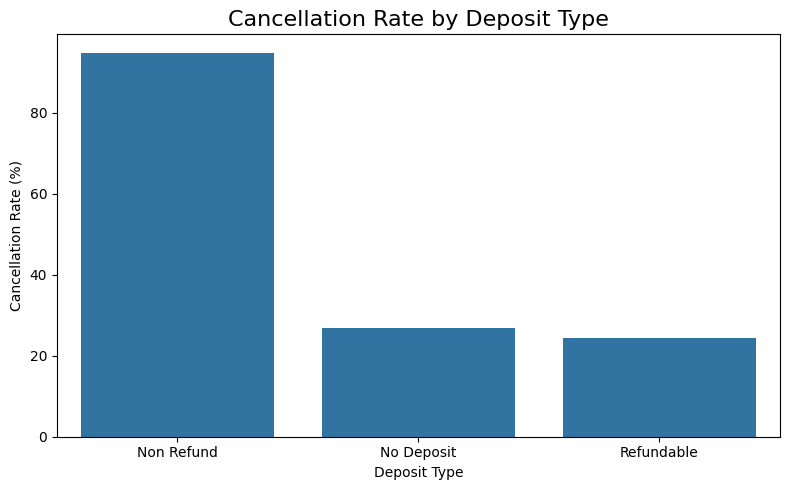

In [ ]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=deposit_cancel_rate.index,
    y=deposit_cancel_rate.values
)

plt.title("Cancellation Rate by Deposit Type", fontsize=16)
plt.xlabel("Deposit Type")
plt.ylabel("Cancellation Rate (%)")
plt.tight_layout()
plt.show()

The Non Refund deposit type has an exceptionally high cancellation rate of 94.70%, compared with 26.87% for No Deposit and 24.30% for Refundable bookings. This shows a very strong association between deposit type and cancellation behavior, with Non Refund bookings having a substantially higher cancellation rate.

In [ ]:
deposit_summary = df_clean.groupby("deposit_type").agg(
    total_bookings=("is_canceled", "count"),
    cancellations=("is_canceled", "sum"),
    cancellation_rate=("is_canceled", "mean")
)

deposit_summary["cancellation_rate"] *= 100

deposit_summary.sort_values(
    "cancellation_rate",
    ascending=False
)

,total_bookings,cancellations,cancellation_rate
deposit_type,,,
Non Refund,1038,983,94.701349
No Deposit,85493,22977,26.875885
Refundable,107,26,24.299065


In [ ]:
customer_cancel_rate = (
    df_clean.groupby("customer_type")["is_canceled"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

customer_cancel_rate

,is_canceled
customer_type,
Transient,30.322563
Contract,16.415518
Transient-Party,15.330980
Group,9.888060


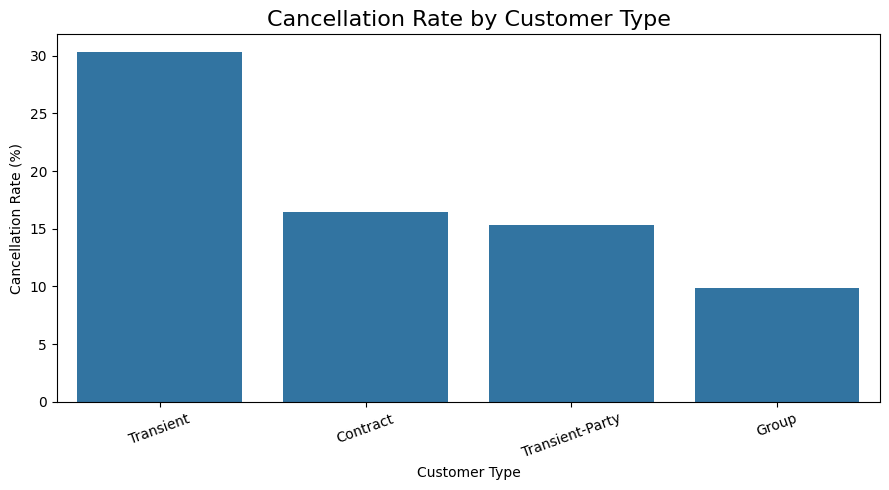

In [ ]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=customer_cancel_rate.index,
    y=customer_cancel_rate.values
)

plt.title("Cancellation Rate by Customer Type", fontsize=16)
plt.xlabel("Customer Type")
plt.ylabel("Cancellation Rate (%)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

Transient customers have the highest cancellation rate at 30.32%, followed by Contract customers at 16.42% and Transient-Party customers at 15.30%. Group customers have the lowest cancellation rate at 9.89%. This indicates noticeable differences in cancellation behavior across customer types, with Transient customers showing a substantially higher cancellation rate than the other categories.

In [ ]:
customer_summary = df_clean.groupby("customer_type").agg(
    total_bookings=("is_canceled", "count"),
    cancellations=("is_canceled", "sum"),
    cancellation_rate=("is_canceled", "mean")
)

customer_summary["cancellation_rate"] *= 100

customer_summary.sort_values(
    "cancellation_rate",
    ascending=False
)

,total_bookings,cancellations,cancellation_rate
customer_type,,,
Transient,71366,21640,30.322563
Contract,3119,512,16.415518
Transient-Party,11617,1781,15.330980
Group,536,53,9.888060


In [ ]:
month_order = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

month_cancel_rate = (
    df_clean.groupby("arrival_date_month")["is_canceled"]
    .mean()
    .mul(100)
    .reindex(month_order)
)

month_cancel_rate

,is_canceled
arrival_date_month,
January,22.294092
February,23.300166
March,24.559753
April,30.533672
May,29.411765
June,30.449424
July,31.988386
August,32.356620
September,24.628323


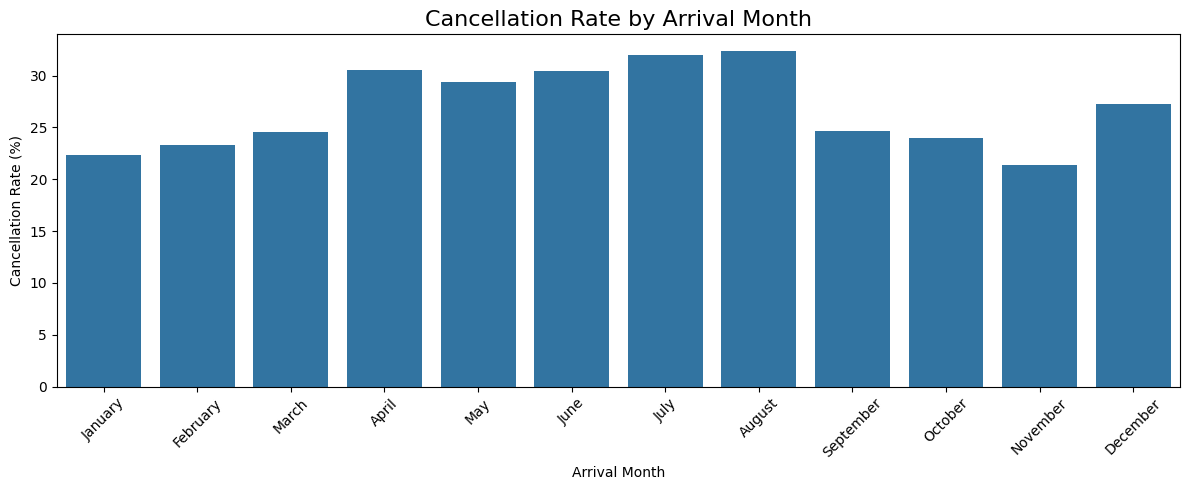

In [ ]:
plt.figure(figsize=(12, 5))

sns.barplot(
    x=month_cancel_rate.index,
    y=month_cancel_rate.values
)

plt.title("Cancellation Rate by Arrival Month", fontsize=16)
plt.xlabel("Arrival Month")
plt.ylabel("Cancellation Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Cancellation rates vary across arrival months. August has the highest cancellation rate at 32.33%, followed by July (31.99%), while November has the lowest rate at 21.40%. Cancellation rates are generally higher from April to August, reaching above 29%, whereas January, February, September, October, and November have relatively lower rates. This indicates a noticeable seasonal variation in cancellation behavior.

In [ ]:
month_summary = df_clean.groupby("arrival_date_month").agg(
    total_bookings=("is_canceled", "count"),
    cancellations=("is_canceled", "sum"),
    cancellation_rate=("is_canceled", "mean")
)

month_summary["cancellation_rate"] *= 100

month_summary = month_summary.reindex(month_order)

month_summary

,total_bookings,cancellations,cancellation_rate
arrival_date_month,,,
January,4638,1034,22.294092
February,6030,1405,23.300166
March,7439,1827,24.559753
April,7870,2403,30.533672
May,8296,2440,29.411765
June,7721,2351,30.449424
July,9988,3195,31.988386
August,11194,3622,32.356620
September,6659,1640,24.628323


In [ ]:
room_reserved_cancel_rate = (
    df_clean.groupby("reserved_room_type")["is_canceled"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

room_reserved_cancel_rate

,is_canceled
reserved_room_type,
H,41.047297
G,36.216216
L,33.333333
C,32.560706
B,31.987891
F,30.338681
D,30.253267
E,27.416667
A,26.181507


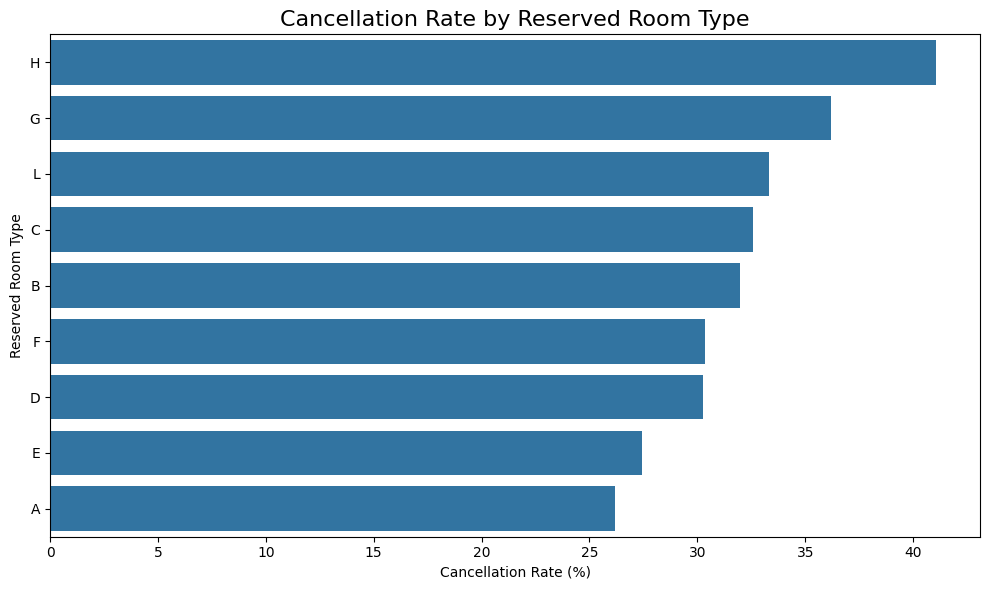

In [ ]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=room_reserved_cancel_rate.values,
    y=room_reserved_cancel_rate.index
)

plt.title("Cancellation Rate by Reserved Room Type", fontsize=16)
plt.xlabel("Cancellation Rate (%)")
plt.ylabel("Reserved Room Type")
plt.tight_layout()
plt.show()

The H room type has the highest cancellation rate at 41.05%, followed by G (36.22%) and L (33.33%). In contrast, A room type has the lowest cancellation rate at 26.18%, followed by E (27.42%). Overall, cancellation rates vary across reserved room types, with H, G, and L showing relatively higher cancellation rates.

In [ ]:
reserved_room_summary = df_clean.groupby("reserved_room_type").agg(
    total_bookings=("is_canceled", "count"),
    cancellations=("is_canceled", "sum"),
    cancellation_rate=("is_canceled", "mean")
)

reserved_room_summary["cancellation_rate"] *= 100

reserved_room_summary.sort_values(
    "cancellation_rate",
    ascending=False
)

,total_bookings,cancellations,cancellation_rate
reserved_room_type,,,
H,592,243,41.047297
G,2035,737,36.216216
L,6,2,33.333333
C,906,295,32.560706
B,991,317,31.987891
F,2805,851,30.338681
D,17294,5232,30.253267
E,6000,1645,27.416667
A,56009,14664,26.181507


In [ ]:
assigned_room_cancel_rate = (
    df_clean.groupby("assigned_room_type")["is_canceled"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

assigned_room_cancel_rate

,is_canceled
assigned_room_type,
L,100.000000
H,35.520685
A,30.727505
G,30.350665
F,24.805771
D,24.312338
E,23.672443
B,22.043309
C,18.457944


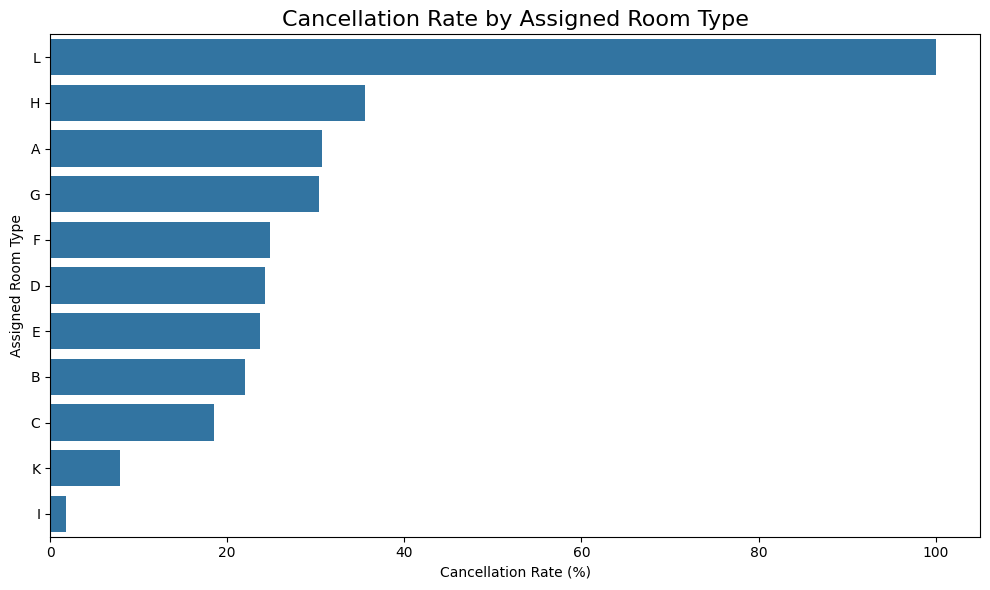

In [ ]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=assigned_room_cancel_rate.values,
    y=assigned_room_cancel_rate.index
)

plt.title("Cancellation Rate by Assigned Room Type", fontsize=16)
plt.xlabel("Cancellation Rate (%)")
plt.ylabel("Assigned Room Type")
plt.tight_layout()
plt.show()

The L assigned room type shows a 100% cancellation rate, but it is based on only 1 booking, so this result is not representative. Among the more meaningful categories, H has the highest cancellation rate at 35.52%, followed by A (30.73%) and G (30.35%). I has the lowest cancellation rate at 1.84%, followed by K (7.94%). Overall, cancellation rates vary considerably across assigned room types.

In [ ]:
assigned_room_summary = df_clean.groupby("assigned_room_type").agg(
    total_bookings=("is_canceled", "count"),
    cancellations=("is_canceled", "sum"),
    cancellation_rate=("is_canceled", "mean")
)

assigned_room_summary["cancellation_rate"] *= 100

assigned_room_summary.sort_values(
    "cancellation_rate",
    ascending=False
)

,total_bookings,cancellations,cancellation_rate
assigned_room_type,,,
L,1,1,100.000000
H,701,249,35.520685
A,46089,14162,30.727505
G,2481,753,30.350665
F,3604,894,24.805771
D,22322,5427,24.312338
E,7156,1694,23.672443
B,1801,397,22.043309
C,2140,395,18.457944


In [ ]:
binary_cols = [
    "is_repeated_guest",
    "has_company",
    "has_agent"
]

binary_cancel_rates = {}

for col in binary_cols:
    binary_cancel_rates[col] = (
        df_clean.groupby(col)["is_canceled"]
        .mean()
        .mul(100)
    )

binary_cancel_rates

{'is_repeated_guest': is_repeated_guest
 0    28.417611
 1     8.237913
 Name: is_canceled, dtype: float64,
 'has_company': has_company
 0    28.751166
 1    10.889749
 Name: is_canceled, dtype: float64,
 'has_agent': has_agent
 0    12.878408
 1    30.056240
 Name: is_canceled, dtype: float64}

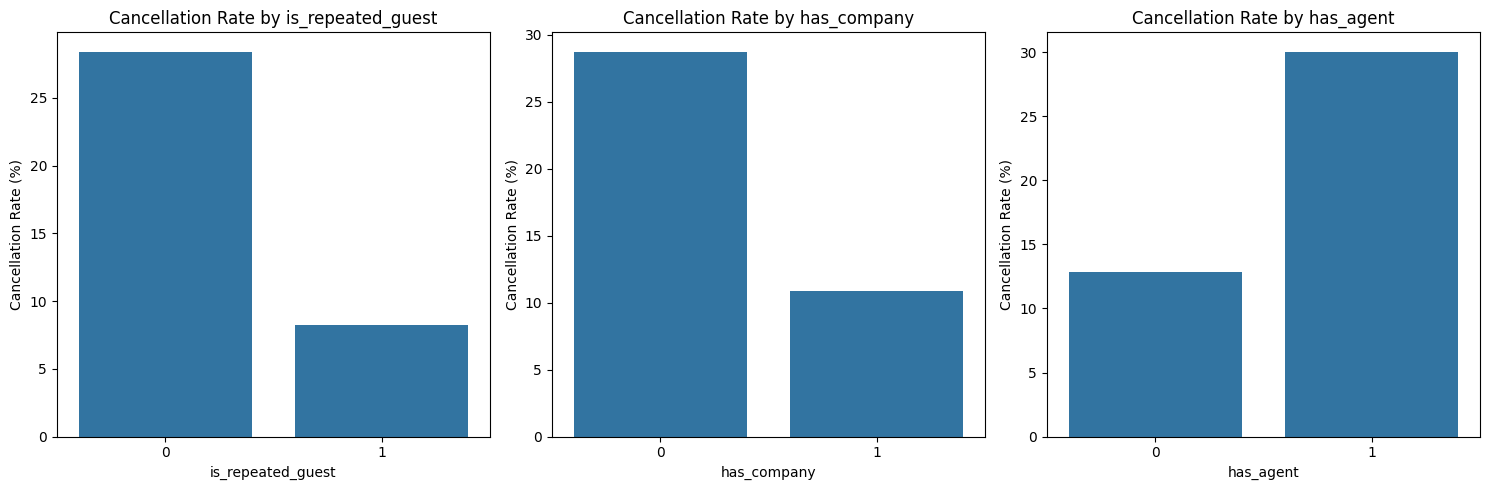

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, col in zip(axes, binary_cols):

    rate = (
        df_clean.groupby(col)["is_canceled"]
        .mean()
        .mul(100)
    )

    sns.barplot(
        x=rate.index,
        y=rate.values,
        ax=ax
    )

    ax.set_title(f"Cancellation Rate by {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Cancellation Rate (%)")

plt.tight_layout()
plt.show()

Repeat guests have a much lower cancellation rate (8.24%) compared with non-repeat guests (28.41%). Bookings with a recorded company ID also have a lower cancellation rate (10.89%) than bookings without a company ID (28.75%). In contrast, bookings with an agent ID have a higher cancellation rate (30.05%) compared with bookings without an agent ID (12.86%). Overall, these booking characteristics show noticeable differences in cancellation behavior.

In [ ]:
binary_summary = []

for col in binary_cols:

    summary = df_clean.groupby(col).agg(
        total_bookings=("is_canceled", "count"),
        cancellations=("is_canceled", "sum"),
        cancellation_rate=("is_canceled", "mean")
    )

    summary["cancellation_rate"] *= 100
    summary["variable"] = col
    summary["category"] = summary.index

    binary_summary.append(
        summary.reset_index(drop=True)
    )

binary_summary = pd.concat(
    binary_summary,
    ignore_index=True
)

binary_summary[
    ["variable", "category", "total_bookings",
     "cancellations", "cancellation_rate"]
]

,variable,category,total_bookings,cancellations,cancellation_rate
0,is_repeated_guest,0,83494,23727,28.417611
1,is_repeated_guest,1,3144,259,8.237913
2,has_company,0,81468,23423,28.751166
3,has_company,1,5170,563,10.889749
4,has_agent,0,11958,1540,12.878408
5,has_agent,1,74680,22446,30.056240


In [ ]:
df_clean["cancellation_status"] = df_clean["is_canceled"].map({
    0: "Not Canceled",
    1: "Canceled"
})

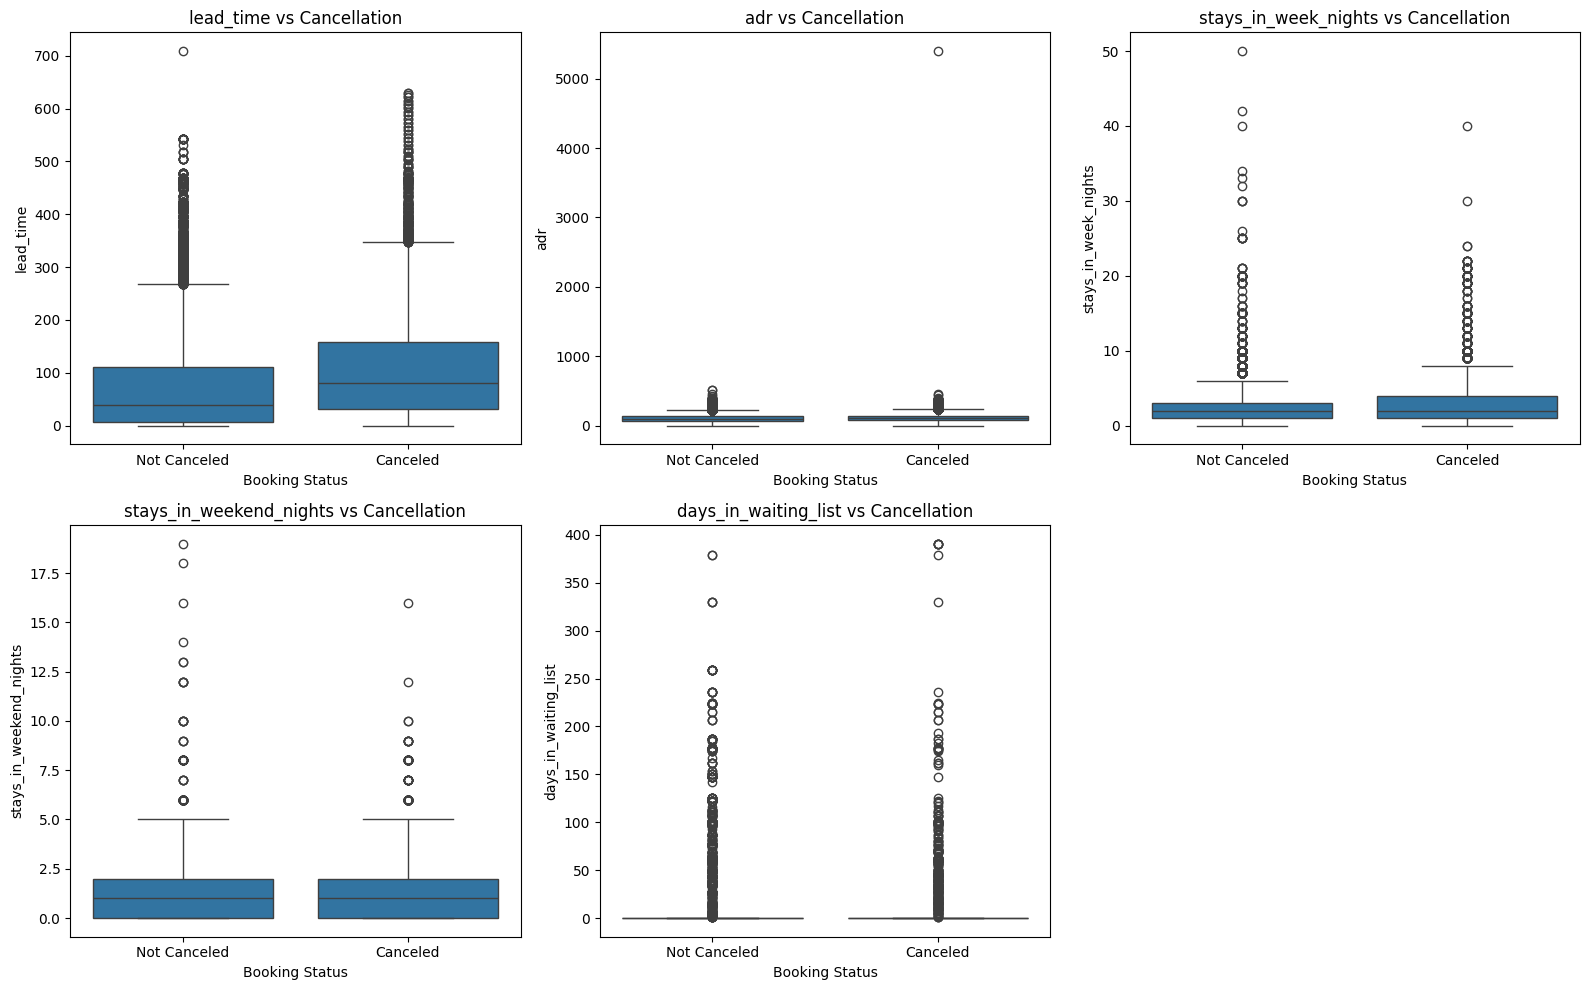

In [ ]:
numerical_cols = [
    "lead_time",
    "adr",
    "stays_in_week_nights",
    "stays_in_weekend_nights",
    "days_in_waiting_list"
]

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for ax, col in zip(axes, numerical_cols):
    sns.boxplot(
        data=df_clean,
        x="cancellation_status",
        y=col,
        ax=ax
    )

    ax.set_title(f"{col} vs Cancellation")
    ax.set_xlabel("Booking Status")
    ax.set_ylabel(col)

# Hide the unused 6th subplot
axes[-1].set_visible(False)

plt.tight_layout()
plt.show()

Cancelled bookings generally show higher values for lead time, ADR, weeknight stays, weekend stays, and days in the waiting list compared with non-cancelled bookings. The largest difference is observed in lead time, where the median is 80 days for cancelled bookings compared with 38 days for non-cancelled bookings. ADR also shows a higher median for cancelled bookings (109.8) than non-cancelled bookings (95.0). The median stay durations are similar between the two groups, while the median waiting-list duration is 0 days for both groups.

In [ ]:
numerical_summary = (
    df_clean
    .groupby("cancellation_status")[numerical_cols]
    .median()
    .T
)

numerical_summary

cancellation_status,Canceled,Not Canceled
lead_time,80.0,38.0
adr,109.8,95.0
stays_in_week_nights,2.0,2.0
stays_in_weekend_nights,1.0,1.0
days_in_waiting_list,0.0,0.0


In [ ]:
numerical_mean_summary = (
    df_clean
    .groupby("cancellation_status")[numerical_cols]
    .mean()
    .T
)

numerical_mean_summary

cancellation_status,Canceled,Not Canceled
lead_time,105.819145,70.518738
adr,117.963968,103.142605
stays_in_week_nights,2.905278,2.540909
stays_in_weekend_nights,1.107354,0.974702
days_in_waiting_list,0.823522,0.722212


In [ ]:
count_cols = [
    "adults",
    "children",
    "babies",
    "previous_cancellations",
    "previous_bookings_not_canceled",
    "booking_changes",
    "required_car_parking_spaces",
    "total_of_special_requests"
]

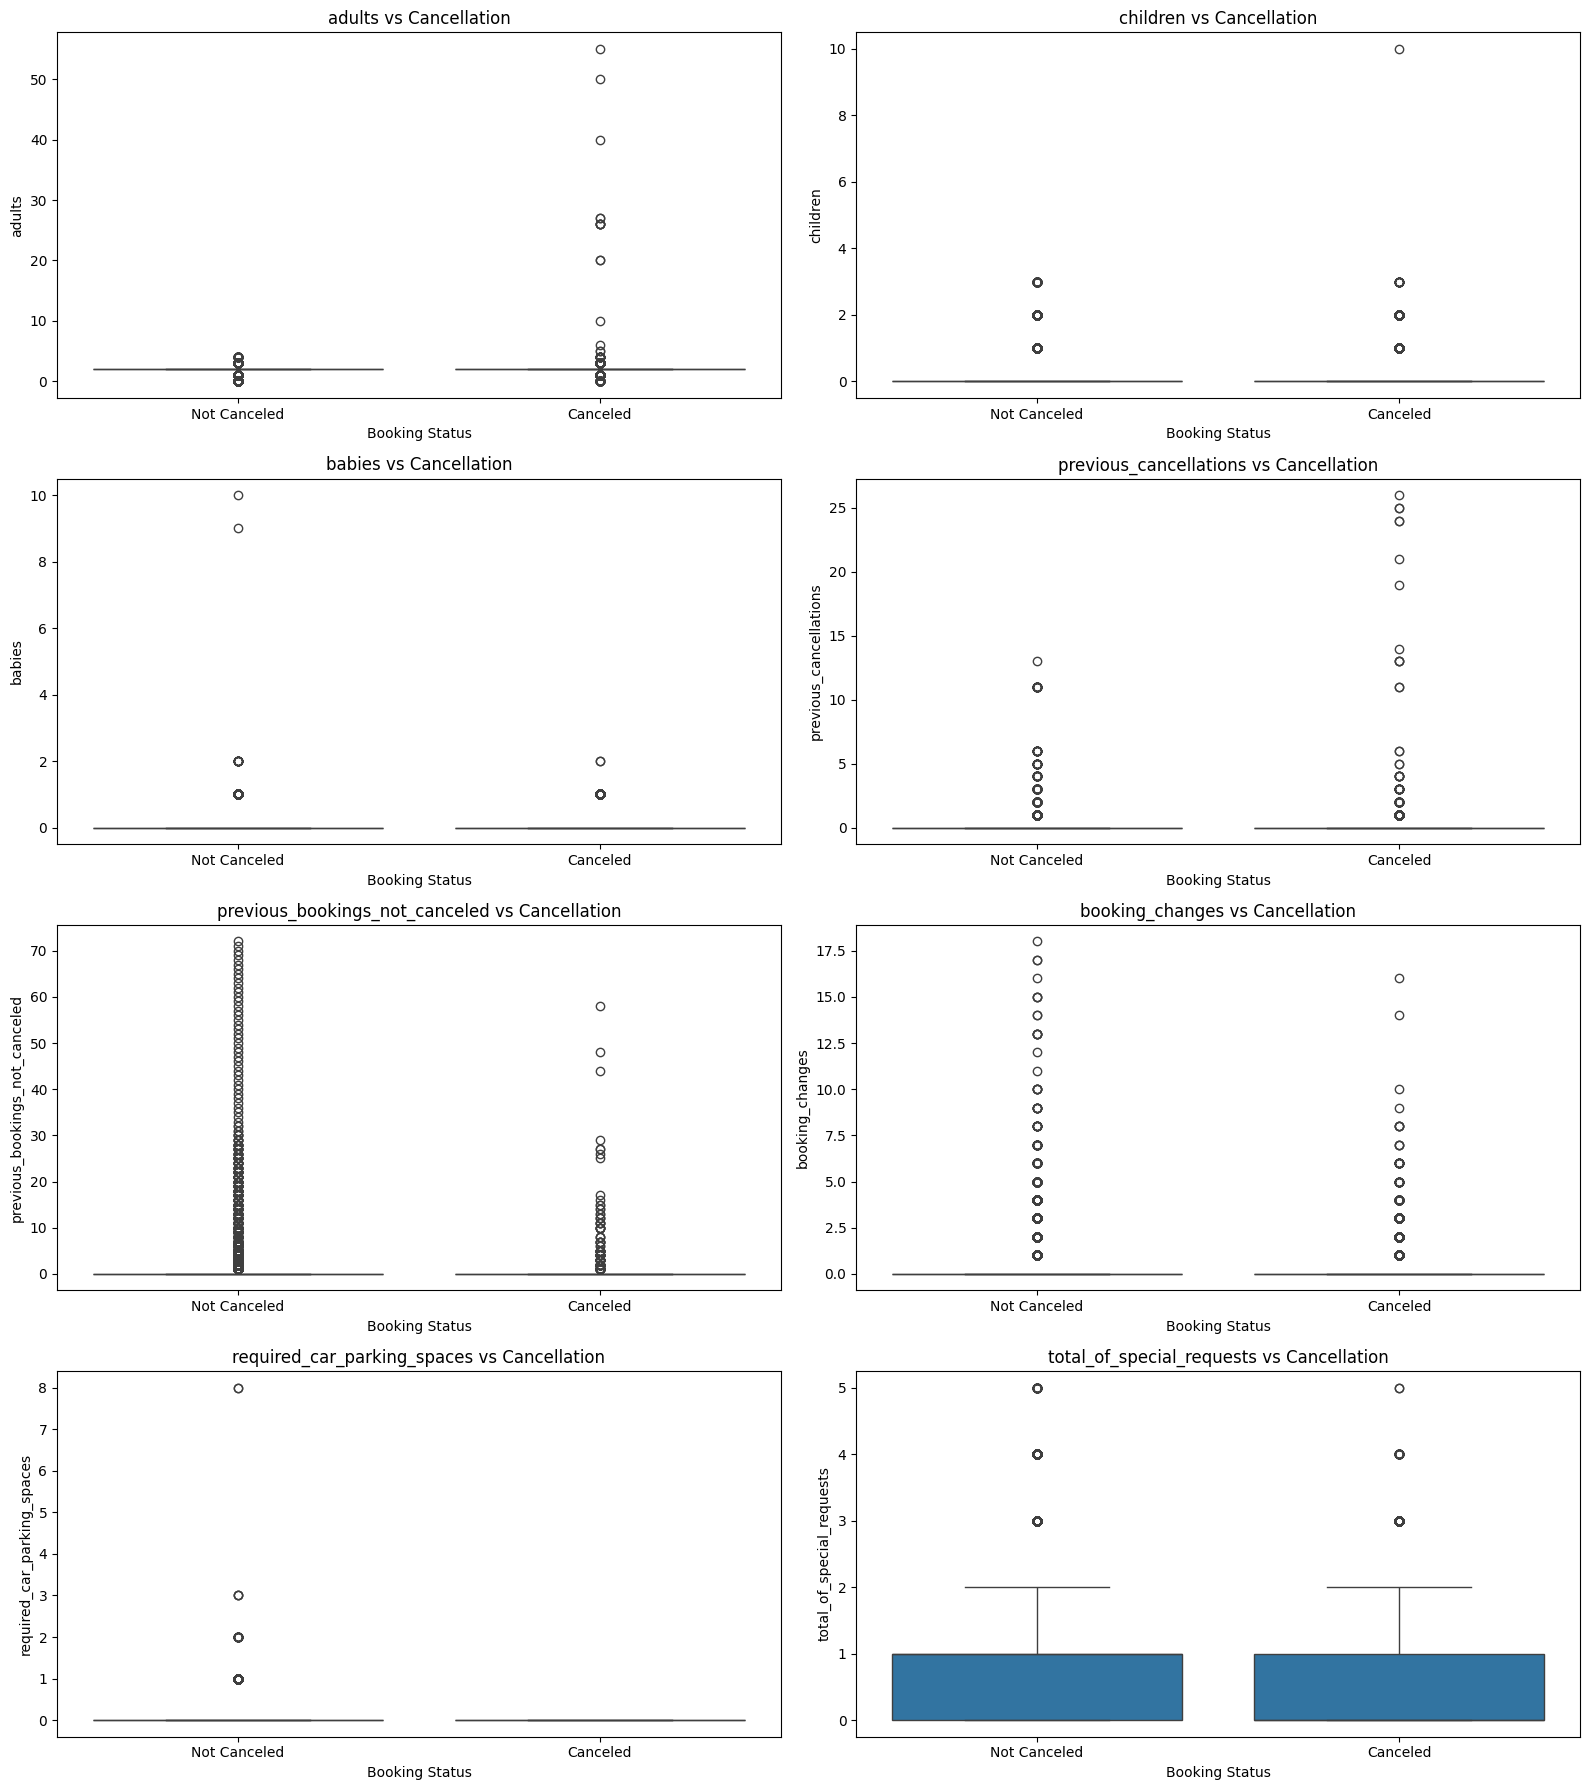

In [ ]:
count_cols = [
    "adults",
    "children",
    "babies",
    "previous_cancellations",
    "previous_bookings_not_canceled",
    "booking_changes",
    "required_car_parking_spaces",
    "total_of_special_requests"
]

fig, axes = plt.subplots(4, 2, figsize=(16, 18))
axes = axes.flatten()

for ax, col in zip(axes, count_cols):
    sns.boxplot(
        data=df_clean,
        x="cancellation_status",
        y=col,
        ax=ax
    )

    ax.set_title(f"{col} vs Cancellation")
    ax.set_xlabel("Booking Status")
    ax.set_ylabel(col)

plt.tight_layout()
plt.show()

Cancelled bookings show slightly higher average numbers of adults,
children, and previous cancellations. In contrast, non-cancelled
bookings have higher averages for previous bookings that were not
canceled, booking changes, required parking spaces, and special
requests. Most variables have a median of zero in both groups because
they are highly concentrated at zero. Extreme observations will be
investigated during the outlier analysis stage.

In [ ]:
count_median_summary = (
    df_clean
    .groupby("cancellation_status")[count_cols]
    .median()
    .T
)

count_median_summary

cancellation_status,Canceled,Not Canceled
adults,2.0,2.0
children,0.0,0.0
babies,0.0,0.0
previous_cancellations,0.0,0.0
previous_bookings_not_canceled,0.0,0.0
booking_changes,0.0,0.0
required_car_parking_spaces,0.0,0.0
total_of_special_requests,0.0,1.0


In [ ]:
count_mean_summary = (
    df_clean
    .groupby("cancellation_status")[count_cols]
    .mean()
    .T
)

count_mean_summary

cancellation_status,Canceled,Not Canceled
adults,1.960769,1.849773
children,0.188818,0.120347
babies,0.007046,0.012322
previous_cancellations,0.061327,0.018786
previous_bookings_not_canceled,0.037313,0.240695
booking_changes,0.160844,0.309232
required_car_parking_spaces,0.000000,0.117123
total_of_special_requests,0.535896,0.763088


In [ ]:
numerical_cols = [
    "is_canceled",
    "lead_time",
    "adr",
    "stays_in_week_nights",
    "stays_in_weekend_nights",
    "days_in_waiting_list",
    "adults",
    "children",
    "babies",
    "previous_cancellations",
    "previous_bookings_not_canceled",
    "booking_changes",
    "required_car_parking_spaces",
    "total_of_special_requests"
]

corr_matrix = df_clean[numerical_cols].corr()

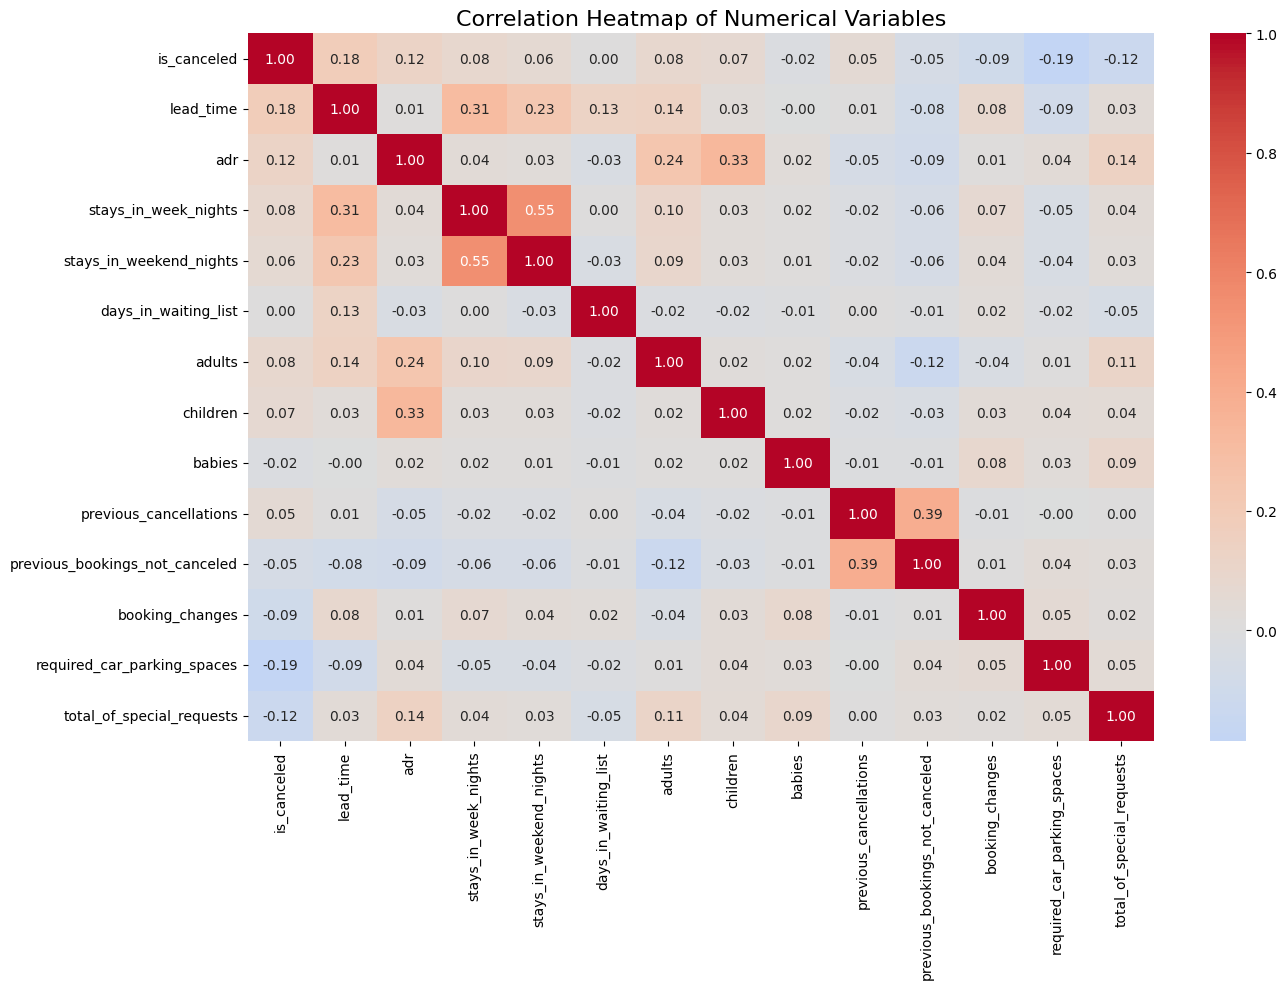

In [ ]:
plt.figure(figsize=(14, 10))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap of Numerical Variables", fontsize=16)
plt.tight_layout()
plt.show()

Insight:
The correlation analysis shows that lead_time has the strongest positive
correlation with cancellation (0.18), while required_car_parking_spaces
has the strongest negative correlation (-0.19). ADR also shows a weak
positive correlation (0.12), whereas total_of_special_requests has a
weak negative correlation (-0.12). Most numerical variables have weak
linear relationships with the target. A moderate correlation is
observed between stays_in_week_nights and stays_in_weekend_nights (0.55).

In [ ]:
target_corr = (
    corr_matrix["is_canceled"]
    .drop("is_canceled")
    .sort_values(key=abs, ascending=False)
)

target_corr

,is_canceled
required_car_parking_spaces,-0.185666
lead_time,0.183507
total_of_special_requests,-0.122086
adr,0.121986
booking_changes,-0.093527
stays_in_week_nights,0.080109
adults,0.079811
children,0.067055
stays_in_weekend_nights,0.057767
previous_bookings_not_canceled,-0.052386


**Multivariate Analysis**

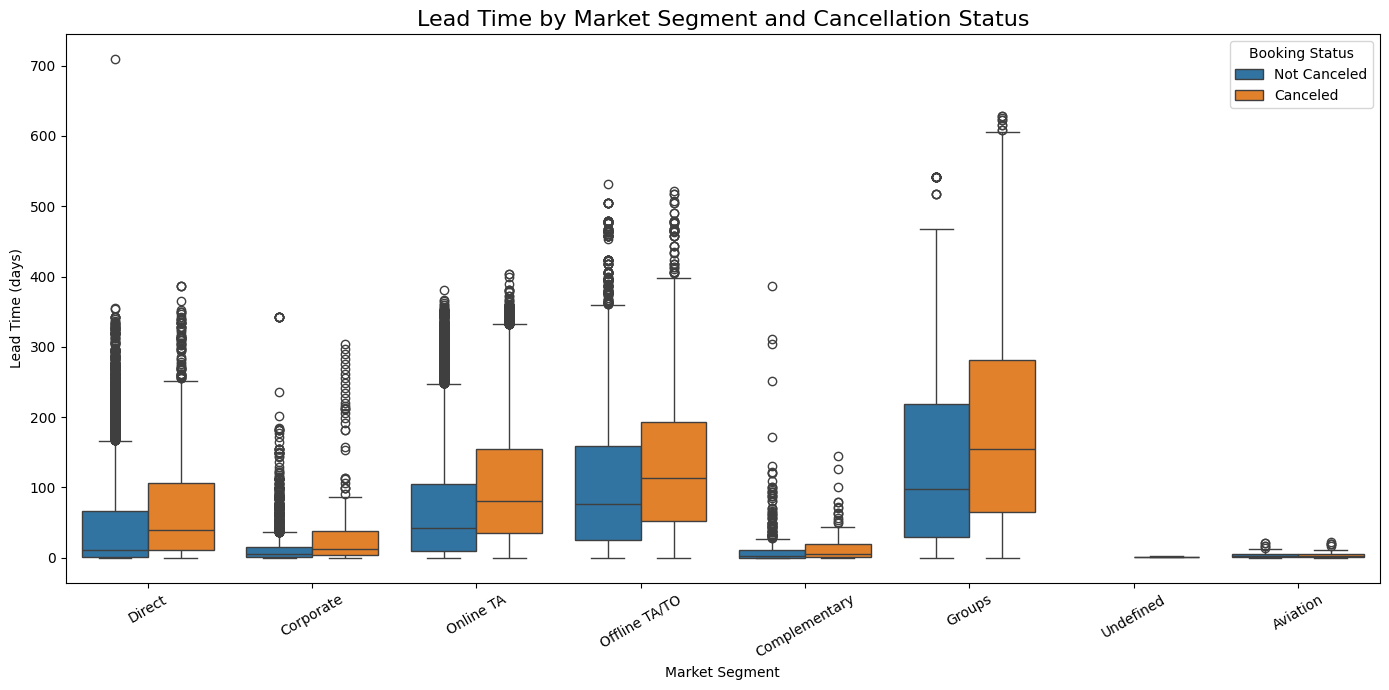

In [ ]:
plt.figure(figsize=(14, 7))

sns.boxplot(
    data=df_clean,
    x="market_segment",
    y="lead_time",
    hue="cancellation_status"
)

plt.title(
    "Lead Time by Market Segment and Cancellation Status",
    fontsize=16
)
plt.xlabel("Market Segment")
plt.ylabel("Lead Time (days)")
plt.xticks(rotation=30)
plt.legend(title="Booking Status")

plt.tight_layout()
plt.show()

Insight:
The relationship between lead time and cancellation varies across market
segments. Cancelled bookings generally have higher median lead times than
non-cancelled bookings, with the largest differences observed in Groups
(155 vs 98 days), Online TA (80 vs 42 days), and Offline TA/TO
(114 vs 77 days). Aviation shows almost no difference. This indicates
that lead time may interact with market segment when explaining
cancellation behavior.

In [ ]:
lead_market_summary = (
    df_clean
    .groupby(["market_segment", "cancellation_status"])["lead_time"]
    .median()
    .unstack()
)

lead_market_summary

cancellation_status,Canceled,Not Canceled
market_segment,,
Aviation,3.0,3.0
Complementary,6.0,3.0
Corporate,13.0,5.0
Direct,40.0,11.0
Groups,155.0,98.0
Offline TA/TO,114.0,77.0
Online TA,80.0,42.0
Undefined,1.5,NaN


In [ ]:
deposit_market_rate = (
    df_clean
    .groupby(["market_segment", "deposit_type"])["is_canceled"]
    .mean()
    .mul(100)
    .unstack()
)

deposit_market_rate

deposit_type,No Deposit,Non Refund,Refundable
market_segment,,,
Aviation,19.819820,NaN,NaN
Complementary,12.170088,NaN,NaN
Corporate,11.276908,70.312500,33.333333
Direct,14.816088,70.000000,33.333333
Groups,16.666667,95.902883,8.750000
Offline TA/TO,13.152029,98.954704,50.000000
Online TA,35.512068,83.333333,100.000000
Undefined,100.000000,NaN,NaN


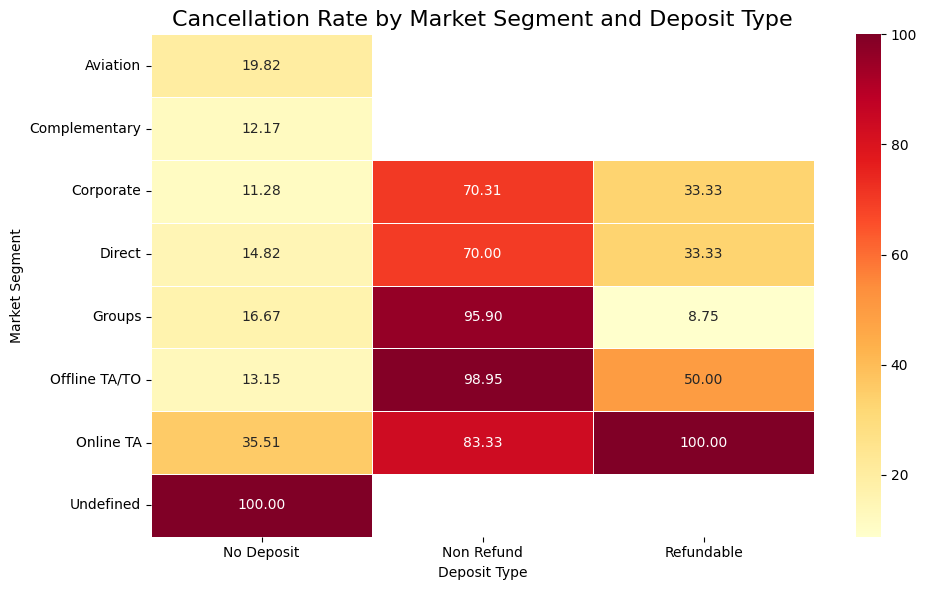

In [ ]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    deposit_market_rate,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd",
    linewidths=0.5
)

plt.title(
    "Cancellation Rate by Market Segment and Deposit Type",
    fontsize=16
)
plt.xlabel("Deposit Type")
plt.ylabel("Market Segment")

plt.tight_layout()
plt.show()

Insight:
Cancellation rates vary substantially across combinations of deposit type
and market segment. For No Deposit bookings, Online TA has the highest
cancellation rate (35.51%), while Corporate has the lowest (11.28%).
Non Refund bookings show very high cancellation rates in several
segments, particularly Offline TA/TO (98.95%) and Groups (95.90%).
However, several combinations have very small sample sizes, so their
cancellation rates should be interpreted cautiously.

In [ ]:
deposit_market_count = (
    df_clean
    .groupby(["market_segment", "deposit_type"])
    .size()
    .unstack(fill_value=0)
)

deposit_market_count

deposit_type,No Deposit,Non Refund,Refundable
market_segment,,,
Aviation,222,0,0
Complementary,682,0,0
Corporate,4088,64,3
Direct,11636,10,6
Groups,4152,659,80
Offline TA/TO,13458,287,4
Online TA,51253,18,14
Undefined,2,0,0


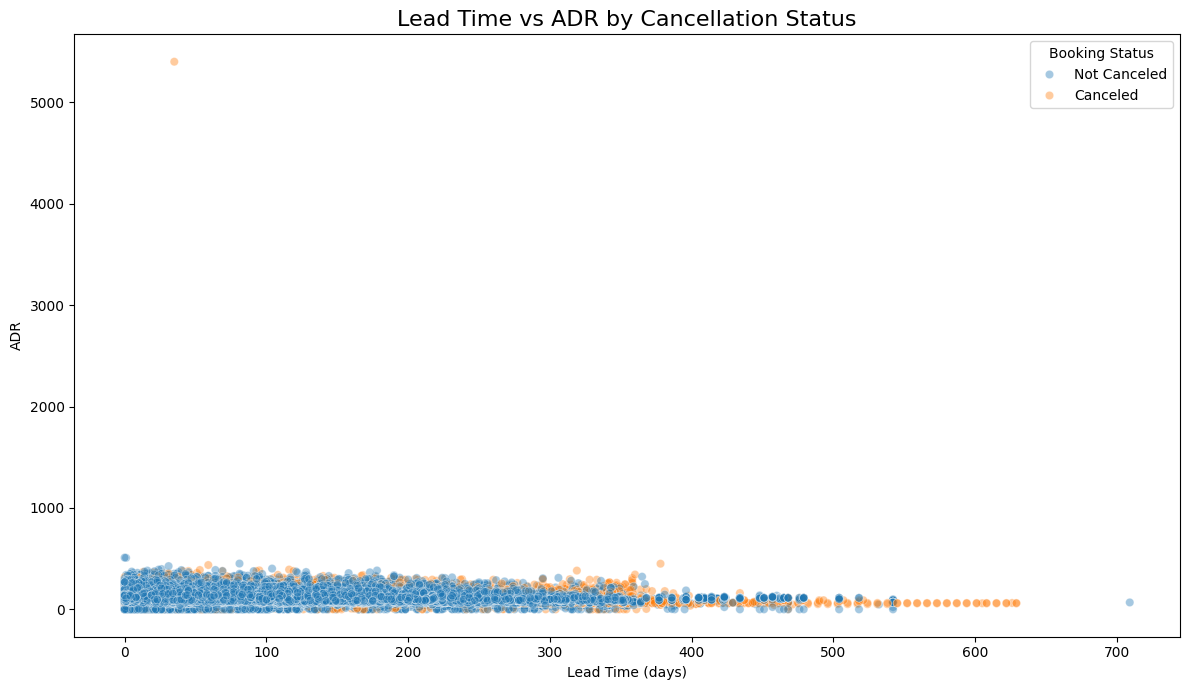

In [ ]:
plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=df_clean,
    x="lead_time",
    y="adr",
    hue="cancellation_status",
    alpha=0.4
)

plt.title(
    "Lead Time vs ADR by Cancellation Status",
    fontsize=16
)
plt.xlabel("Lead Time (days)")
plt.ylabel("ADR")
plt.legend(title="Booking Status")

plt.tight_layout()
plt.show()

Insight:
Cancelled bookings generally have higher lead times and ADR than
non-cancelled bookings. The median lead time is 80 days for cancelled
bookings compared with 38 days for non-cancelled bookings, while the
median ADR is 109.8 compared with 95.0. However, the correlation between
lead time and ADR is very weak in both groups, indicating little linear
relationship between these two variables. Extreme ADR observations will
be investigated during the outlier analysis stage.